# H2: Comprehensive Project — Implementation & Review

**FIT1061 Introduction to Artificial Intelligence — HD Task 2**

H1 defined the problem and justified the approach. H2 is where you build, evaluate, and review. Implement the system you scoped in H1, run honest experiments, and write up what worked, what didn't, and what you'd do differently. H3 then defends the full arc in the W14 interview.

> **Prerequisite:** H1 (Complete). Re-read your H1 problem definition before starting.

> **No milestone discussion at H2.** H1 had the discussion; H3 (W14 interview) defends this work.

> H2 should adapt course techniques to a meaningful problem with more depth than a straightforward earlier task. Optional D4 Coin Clash enrichment is available in OnTrack but is not an assessment benchmark or prerequisite.

## Recap from H1: what I committed to

**Problem (from H1):** After a disruption, a food-rescue coordinator has to drive from a depot to four pickup points before their deadlines. Some road cells may be blocked, but the coordinator does not know which ones at the start. At each decision point, the coordinator can either move towards a pickup or ask a human advisor about one road. The advisor can be wrong, each question uses part of a limited budget, and asking can delay the vehicle. The decision is therefore not only “which route is shortest?” but also “when is asking worth the cost?”

**Technique(s) (from H1):** I use A* to find short routes, Bayesian belief updates to represent how likely each hidden road is blocked, and expectimax to compare asking with moving under uncertainty. The main comparison is between two versions of the same policy. h=1 looks only at the current choice: ask now or act now. h=2 also considers what can happen after moving to the next pickup. It can move first, observe a road, and then decide whether a question is still useful while tracking how many questions remain. In this report, “myopic” means looking only at the current choice, while “budget-aware” means considering the effect of using a question on later choices.

**Data (from H1):** The project uses seeded 16x16 humanitarian-grid scenes with four pickups and six possible hidden roads. Six binary hidden roads create 64 possible blocked/open worlds. Pickup values and deadlines are synthetic but fixed by each seed. The pickup-order evaluator scores all 65 ordered subsets, including the empty route.

**What makes this HD-level (from H1):** The agent does not treat asking as automatically helpful. It weighs the possible value of an answer against wrong answers, consultation delay and the limited question budget. h=2 can also preserve a question for a later decision point, so the project tests sequential information use rather than only shortest-path search.

**Pivot since H1 (if any):** The H1.3 preliminary 40-scene check identified 55 candidate route cells and 35 bottleneck cells, and led to the choice of six hidden roads. Its value-of-information and delay numbers were planning evidence, not final H2 results. H2 rebuilds that scene generation inside this notebook and checks that it reproduces the same hidden roads, values and deadlines for seeds 100–109. The runtime trigger later reduced the exploratory delay settings to 0, 1, 2 and 4. The planned route-threshold sensitivity check and query-synergy metric were not completed, so I record them as limitations below.

In [1]:
# --- SETUP ---
import json
import math
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

print("Setup OK.")

Setup OK.


### Data

#### Scene setup

This section builds the 16×16 humanitarian grid from the P5 disaster-zone layout, with the depot at (0, 0) and the four P5 pickup locations. The whole map and scene generator live in this notebook, so every experiment can be rerun without any external script. The helper functions follow the same route and random-number rules as the H1.3 preliminary check, so the same seed always gives the same scene.

In [2]:
from dataclasses import dataclass
from functools import lru_cache
from heapq import heappop, heappush
import random


@dataclass(frozen=True)
class Grid:
    """The fixed map shared by every scene."""

    size: int
    obstacles: frozenset
    depot: tuple
    pickups: tuple


@dataclass(frozen=True)
class Scene:
    """One seeded scenario with hidden roads and pickup deadlines."""

    seed: int
    hidden_roads: tuple
    values: tuple
    deadlines: tuple


@dataclass(frozen=True)
class Settings:
    """Parameters that define one policy evaluation."""

    p_block: float = 0.5
    accuracy: float = 0.8
    delay: int = 0
    budget: int = 2
    route_threshold: float = 0.5


def disaster_zone_obstacles():
    """Return the fixed obstacle layout used by the P5 humanitarian grid."""

    obstacles = set()

    def add_rectangle(top, left, bottom, right):
        for row in range(top, bottom + 1):
            for column in range(left, right + 1):
                obstacles.add((row, column))

    def add_horizontal_wall(row, left, right):
        for column in range(left, right + 1):
            obstacles.add((row, column))

    def add_vertical_wall(column, top, bottom):
        for row in range(top, bottom + 1):
            obstacles.add((row, column))

    add_rectangle(2, 2, 3, 4)
    add_rectangle(5, 1, 6, 2)
    add_rectangle(8, 4, 9, 5)
    add_rectangle(11, 2, 12, 4)
    add_horizontal_wall(4, 7, 10)
    add_horizontal_wall(5, 7, 12)
    add_horizontal_wall(7, 7, 11)
    add_horizontal_wall(10, 7, 10)
    add_horizontal_wall(13, 5, 11)
    add_horizontal_wall(6, 9, 12)
    add_horizontal_wall(9, 0, 2)
    add_horizontal_wall(9, 10, 13)
    add_vertical_wall(7, 11, 12)
    add_vertical_wall(5, 0, 3)
    add_vertical_wall(9, 3, 3)
    add_vertical_wall(12, 0, 1)
    add_vertical_wall(14, 0, 2)
    add_vertical_wall(14, 5, 8)
    add_vertical_wall(14, 11, 15)
    return frozenset(obstacles)


@lru_cache(maxsize=None)
def shortest_path(grid, blocked_cells, start, goal):
    """Return an A* path using Manhattan distance on the current route map."""

    obstacles = set(grid.obstacles)
    obstacles.update(blocked_cells)
    if start in obstacles or goal in obstacles:
        return None

    def heuristic(cell):
        return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

    frontier = [(heuristic(start), 0, start)]
    parent = {start: None}
    distance = {start: 0}

    while frontier:
        _, travelled, current = heappop(frontier)
        if travelled != distance[current]:
            continue
        if current == goal:
            path = []
            while current is not None:
                path.append(current)
                current = parent[current]
            return path[::-1]

        row, column = current
        neighbours = (
            (row - 1, column),
            (row + 1, column),
            (row, column - 1),
            (row, column + 1),
        )
        for next_cell in neighbours:
            next_row, next_column = next_cell
            inside_grid = (
                0 <= next_row < grid.size
                and 0 <= next_column < grid.size
            )
            if not inside_grid or next_cell in obstacles:
                continue
            next_distance = travelled + 1
            if next_distance < distance.get(next_cell, math.inf):
                distance[next_cell] = next_distance
                parent[next_cell] = current
                priority = next_distance + heuristic(next_cell)
                heappush(frontier, (priority, next_distance, next_cell))

    return None




def route_cells(grid):
    """Return cells on the selected shortest routes between key locations."""

    locations = (grid.depot,) + grid.pickups
    cells = set()
    for start in locations:
        for goal in locations:
            path = shortest_path(grid, frozenset(), start, goal)
            if path:
                cells.update(path[1:-1])
    cells.difference_update(locations)
    return tuple(sorted(cells))


def bottleneck_cells(grid, candidate_cells):
    """Keep cells whose blockage lengthens at least one key trip."""

    locations = (grid.depot,) + grid.pickups
    base_distances = {}
    for start_index in range(len(locations)):
        for goal_index in range(start_index + 1, len(locations)):
            path = shortest_path(
                grid,
                frozenset(),
                locations[start_index],
                locations[goal_index],
            )
            base_distances[(start_index, goal_index)] = (
                math.inf if path is None else len(path) - 1
            )

    bottlenecks = []
    for cell in candidate_cells:
        closed_cells = frozenset({cell})
        becomes_longer = False
        for (start_index, goal_index), base_distance in base_distances.items():
            path = shortest_path(
                grid,
                closed_cells,
                locations[start_index],
                locations[goal_index],
            )
            new_distance = math.inf if path is None else len(path) - 1
            if new_distance > base_distance:
                becomes_longer = True
                break
        if becomes_longer:
            bottlenecks.append(cell)
    return tuple(bottlenecks)


def make_scene(grid, bottlenecks, seed):
    """Return one seeded scene using the H1 random-generation order."""

    random_generator = random.Random(seed)
    hidden_roads = tuple(random_generator.sample(bottlenecks, 6))
    values = tuple(
        random_generator.randint(8, 20)
        for _ in grid.pickups
    )

    reference_order = list(range(len(grid.pickups)))
    random_generator.shuffle(reference_order)
    arrival_times = [None] * len(grid.pickups)
    elapsed_time = 0
    current = grid.depot
    for pickup_index in reference_order:
        path = shortest_path(
            grid,
            frozenset(),
            current,
            grid.pickups[pickup_index],
        )
        elapsed_time += len(path) - 1 if path else 20
        arrival_times[pickup_index] = elapsed_time
        current = grid.pickups[pickup_index]

    deadlines = tuple(
        max(10, arrival_times[index] + random_generator.randint(0, 20))
        for index in range(len(grid.pickups))
    )
    return Scene(
        seed=seed,
        hidden_roads=hidden_roads,
        values=values,
        deadlines=deadlines,
    )


#### Scene data and calibration seeds

The map first produces 55 candidate route cells, then keeps the 35 bottleneck cells whose blockage makes at least one key trip longer. Each scene draws six hidden roads from these bottlenecks, pickup values from 8 to 20, and deadlines from a reference tour plus 0–20 steps of slack. Seeds 100–109 are used only for calibration and checks; the final experiments use the separate seeds 200–249, which were not used during development.

In [3]:
# --- DATA ---
BASE = disaster_zone_obstacles()
GRID = Grid(
    size=16,
    obstacles=BASE,
    depot=(0, 0),
    pickups=((3, 7), (9, 7), (15, 15), (7, 13)),
)
ALL_CANDIDATES = route_cells(GRID)
BOTTLENECKS = bottleneck_cells(GRID, ALL_CANDIDATES)
SCENES = tuple(
    make_scene(GRID, BOTTLENECKS, seed)
    for seed in range(100, 110)
)
assert len(ALL_CANDIDATES) == 55
assert len(BOTTLENECKS) == 35
PRIMARY_SETTINGS = Settings()
print({
    "scenes": len(SCENES),
    "candidate_cells": len(ALL_CANDIDATES),
    "bottleneck_cells": len(BOTTLENECKS),
    "worlds": 2 ** len(SCENES[0].hidden_roads),
    "pickups": len(GRID.pickups),
})

{'scenes': 10, 'candidate_cells': 55, 'bottleneck_cells': 35, 'worlds': 64, 'pickups': 4}


### Implementation

#### World and belief

There are six hidden roads, so the agent can enumerate 64 possible worlds. The policy never receives the true world as part of its state. It only updates a belief from two kinds of evidence: roads observed while driving and noisy answers from the advisor. Evidence is stored in sorted tuples, so the same information produces the same cache key regardless of the order in which it was collected.

In [4]:
def is_blocked(world, road):
    """Return whether the bit for ``road`` is set in this hidden world."""

    return bool(world & (1 << road))


def prior_probability(world, n_roads, p_block):
    """Return the independent-road prior probability of one hidden world."""

    blocked_count = sum(is_blocked(world, road) for road in range(n_roads))
    open_count = n_roads - blocked_count
    return p_block ** blocked_count * (1.0 - p_block) ** open_count


@dataclass(frozen=True)
class Evidence:
    """Immutable observations and advisor answers collected so far."""

    seen: tuple = ()
    answers: tuple = ()


def _add_fact(facts, road, state):
    """Add one sorted fact and reject contradictory duplicate evidence."""

    facts = dict(facts)
    if road in facts and facts[road] != state:
        raise ValueError("one road cannot have two observed states")
    facts[road] = state
    return tuple(sorted(facts.items()))


def add_seen(evidence, road, was_blocked):
    """Return evidence after observing one road during movement."""

    return Evidence(
        seen=_add_fact(evidence.seen, road, bool(was_blocked)),
        answers=evidence.answers,
    )


def add_answer(evidence, road, said_blocked):
    """Return evidence after recording one advisor answer."""

    return Evidence(
        seen=evidence.seen,
        answers=_add_fact(evidence.answers, road, bool(said_blocked)),
    )


@lru_cache(maxsize=None)
def belief_from(evidence, n_roads, p_block, accuracy):
    """Rebuild and normalise the world belief implied by the evidence."""

    weights = []
    for world in range(1 << n_roads):
        weight = prior_probability(world, n_roads, p_block)

        for road, was_blocked in evidence.seen:
            if is_blocked(world, road) != was_blocked:
                weight = 0.0
                break

        if weight:
            for road, said_blocked in evidence.answers:
                answer_is_correct = is_blocked(world, road) == said_blocked
                weight *= accuracy if answer_is_correct else 1.0 - accuracy

        weights.append(weight)

    total = sum(weights)
    if total <= 0.0:
        raise ValueError("evidence has zero posterior probability")
    return tuple(weight / total for weight in weights)


def probability_of_answer(belief, road, said_blocked, accuracy):
    """Return the probability of one possible advisor answer."""

    probability = 0.0
    for world, world_probability in enumerate(belief):
        answer_is_correct = is_blocked(world, road) == said_blocked
        likelihood = accuracy if answer_is_correct else 1.0 - accuracy
        probability += world_probability * likelihood
    return probability


def blocked_probability(belief, road):
    """Return the posterior probability that one road is blocked."""

    return sum(
        world_probability
        for world, world_probability in enumerate(belief)
        if is_blocked(world, road)
    )


#### Routes and travel

A* plans with the current belief. Roads that have been observed blocked are always avoided. An unseen road is avoided only when its posterior blockage probability is above the route threshold; otherwise the vehicle may approach it and learn its state. The true world is used only at that observation moment, so the planner cannot see hidden blockages in advance.

In [5]:
@dataclass(frozen=True)
class DriveResult:
    """The observable result of travelling towards one pickup."""

    steps: int
    end: tuple
    evidence: Evidence
    reached: bool


@lru_cache(maxsize=None)
def cells_to_avoid(scene, evidence, settings):
    """Return roads avoided by the current posterior route rule."""

    road_count = len(scene.hidden_roads)
    belief = belief_from(
        evidence,
        road_count,
        settings.p_block,
        settings.accuracy,
    )
    observed = dict(evidence.seen)
    blocked_cells = set()

    for road, cell in enumerate(scene.hidden_roads):
        if observed.get(road) is True:
            blocked_cells.add(cell)
            continue
        if road not in observed:
            blockage_probability = blocked_probability(belief, road)
            if blockage_probability > settings.route_threshold:
                blocked_cells.add(cell)

    return frozenset(blocked_cells)


def _known_blocked_cells(scene, evidence):
    """Return only roads physically observed to be blocked."""

    return frozenset(
        scene.hidden_roads[road]
        for road, was_blocked in evidence.seen
        if was_blocked
    )


@lru_cache(maxsize=None)
def drive(grid, scene, true_world, start, goal, evidence, settings):
    """Travel one cell at a time and reveal a hidden road only when approached."""

    hidden_index = {
        cell: road for road, cell in enumerate(scene.hidden_roads)
    }
    current = start
    steps = 0
    current_evidence = evidence
    maximum_steps = grid.size * grid.size * 4 + len(scene.hidden_roads) * 4

    for _ in range(maximum_steps):
        if current == goal:
            return DriveResult(steps, current, current_evidence, True)

        path = shortest_path(
            grid,
            cells_to_avoid(scene, current_evidence, settings),
            current,
            goal,
        )
        if path is None:
            # A conservative posterior route may be unavailable. In that case,
            # try the map containing only roads already seen to be blocked.
            path = shortest_path(
                grid,
                _known_blocked_cells(scene, current_evidence),
                current,
                goal,
            )
        if path is None:
            return DriveResult(steps, current, current_evidence, False)

        next_cell = path[1]
        road = hidden_index.get(next_cell)
        observed_roads = dict(current_evidence.seen)

        if road is not None and road not in observed_roads:
            # The true world is consulted only because the vehicle has reached
            # the edge of this hidden road and can inspect it physically.
            was_blocked = is_blocked(true_world, road)
            current_evidence = add_seen(current_evidence, road, was_blocked)
            if was_blocked:
                continue

        current = next_cell
        steps += 1

    raise RuntimeError("travel exceeded the grid-step limit")


#### Pickup ordering

The pickup-order section scores all 65 ordered subsets, but the policy commits only to the next pickup and replans after each arrival. A sequence is scored by actually travelling each leg under the current evidence. The planner can therefore compare different future orders without pretending that the whole route is fixed in advance.

In [6]:
@dataclass(frozen=True)
class State:
    """Information available to a policy at one decision point."""

    position: tuple
    time: int
    remaining: frozenset
    evidence: Evidence
    asked: frozenset = frozenset()
    budget_left: int = 0


def all_sequences(n_pickups):
    """Return every ordered subset, including the empty sequence."""

    sequences = [()]

    def extend(prefix, choices):
        for pickup in choices:
            next_prefix = prefix + (pickup,)
            sequences.append(next_prefix)
            next_choices = tuple(choice for choice in choices if choice != pickup)
            extend(next_prefix, next_choices)

    extend((), tuple(range(n_pickups)))
    return sequences


@lru_cache(maxsize=None)
def sequence_value(grid, scene, true_world, state, sequence, settings):
    """Return rescued value when one world follows one candidate sequence."""

    current_position = state.position
    current_time = state.time
    current_evidence = state.evidence
    rescued_value = 0.0

    for pickup in sequence:
        if pickup not in state.remaining:
            continue

        result = drive(
            grid,
            scene,
            true_world,
            current_position,
            grid.pickups[pickup],
            current_evidence,
            settings,
        )
        current_position = result.end
        current_time += result.steps
        current_evidence = result.evidence

        reached_before_deadline = (
            result.reached
            and current_time <= scene.deadlines[pickup]
        )
        if reached_before_deadline:
            rescued_value += scene.values[pickup]

    return rescued_value


@lru_cache(maxsize=None)
def best_next_pickup(grid, scene, state, settings):
    """Return the first pickup from the best sequence under the current belief."""

    if not state.remaining:
        return None

    belief = belief_from(
        state.evidence,
        len(scene.hidden_roads),
        settings.p_block,
        settings.accuracy,
    )
    best_sequence = ()
    best_estimate = -math.inf

    for sequence in all_sequences(len(grid.pickups)):
        if not sequence:
            continue
        if any(pickup not in state.remaining for pickup in sequence):
            continue

        expected_value = sum(
            world_probability
            * sequence_value(grid, scene, world, state, sequence, settings)
            for world, world_probability in enumerate(belief)
            if world_probability > 0.0
        )
        if expected_value > best_estimate + 1e-10:
            best_sequence = sequence
            best_estimate = expected_value

    return best_sequence[0] if best_sequence else None


#### Policies

The policies share the same state representation and travel model. Never-ask replans after each pickup without consulting the advisor. Always-ask follows a simple baseline that asks about the first unknown road on the current planned route. The finite-horizon expectimax policy can ask, act, or move to a pickup and keep its remaining budget for a later decision. The omniscient policy is an upper bound with every hidden road known from the start.

In [7]:
def _belief_for_state(scene, state, settings):
    """Return the posterior belief represented by one policy state."""

    return belief_from(
        state.evidence,
        len(scene.hidden_roads),
        settings.p_block,
        settings.accuracy,
    )


@lru_cache(maxsize=None)
def value_never_ask(grid, scene, state, settings):
    """Return expected rescued value when the agent never asks."""

    if not state.remaining:
        return 0.0

    next_pickup = best_next_pickup(grid, scene, state, settings)
    if next_pickup is None:
        return 0.0

    belief = _belief_for_state(scene, state, settings)
    expected_value = 0.0
    for world, world_probability in enumerate(belief):
        if world_probability <= 0.0:
            continue
        result = drive(
            grid,
            scene,
            world,
            state.position,
            grid.pickups[next_pickup],
            state.evidence,
            settings,
        )
        arrival_time = state.time + result.steps
        reward = (
            scene.values[next_pickup]
            if result.reached and arrival_time <= scene.deadlines[next_pickup]
            else 0.0
        )
        child_state = State(
            position=result.end,
            time=arrival_time,
            remaining=state.remaining - {next_pickup},
            evidence=result.evidence,
            asked=state.asked,
            budget_left=state.budget_left,
        )
        expected_value += world_probability * (
            reward + value_never_ask(grid, scene, child_state, settings)
        )
    return expected_value


def _planned_path(grid, scene, state, settings, target):
    """Return the route currently planned for one target."""

    path = shortest_path(
        grid,
        cells_to_avoid(scene, state.evidence, settings),
        state.position,
        grid.pickups[target],
    )
    if path is None:
        path = shortest_path(
            grid,
            _known_blocked_cells(scene, state.evidence),
            state.position,
            grid.pickups[target],
        )
    return path


def _first_unknown_on_path(scene, path, evidence, asked):
    """Return the first hidden road not queried or physically observed."""

    hidden_index = {
        cell: road for road, cell in enumerate(scene.hidden_roads)
    }
    seen = {road for road, _ in evidence.seen}
    for cell in path[1:] if path else ():
        road = hidden_index.get(cell)
        if road is not None and road not in seen and road not in asked:
            return road
    return None


@lru_cache(maxsize=None)
def value_always_ask(grid, scene, state, settings):
    """Return expected value for the nearest-unknown-road asking baseline."""

    if state.budget_left <= 0 or not state.remaining:
        return value_never_ask(grid, scene, state, settings)

    next_pickup = best_next_pickup(grid, scene, state, settings)
    if next_pickup is None:
        return value_never_ask(grid, scene, state, settings)
    path = _planned_path(grid, scene, state, settings, next_pickup)
    query = _first_unknown_on_path(scene, path, state.evidence, state.asked)
    if query is None:
        return value_never_ask(grid, scene, state, settings)

    belief = _belief_for_state(scene, state, settings)
    expected_value = 0.0
    for said_blocked in (False, True):
        answer_probability = probability_of_answer(
            belief,
            query,
            said_blocked,
            settings.accuracy,
        )
        if answer_probability <= 0.0:
            continue
        child_state = State(
            position=state.position,
            time=state.time + settings.delay,
            remaining=state.remaining,
            evidence=add_answer(state.evidence, query, said_blocked),
            asked=state.asked | {query},
            budget_left=state.budget_left - 1,
        )
        expected_value += answer_probability * value_always_ask(
            grid,
            scene,
            child_state,
            settings,
        )
    return expected_value


def value_lookahead(grid, scene, state, settings, horizon):
    """Return expectimax value and action for a finite movement horizon."""

    @lru_cache(maxsize=None)
    def solve(current_state, current_horizon):
        best_value = value_never_ask(grid, scene, current_state, settings)
        best_action = ("act",)

        if current_state.budget_left > 0:
            belief = _belief_for_state(scene, current_state, settings)
            seen_roads = {road for road, _ in current_state.evidence.seen}
            for query in range(len(scene.hidden_roads)):
                if query in seen_roads or query in current_state.asked:
                    continue

                ask_value = 0.0
                for said_blocked in (False, True):
                    answer_probability = probability_of_answer(
                        belief,
                        query,
                        said_blocked,
                        settings.accuracy,
                    )
                    if answer_probability <= 0.0:
                        continue
                    child_state = State(
                        position=current_state.position,
                        time=current_state.time + settings.delay,
                        remaining=current_state.remaining,
                        evidence=add_answer(
                            current_state.evidence,
                            query,
                            said_blocked,
                        ),
                        asked=current_state.asked | {query},
                        budget_left=current_state.budget_left - 1,
                    )
                    child_value, _ = solve(child_state, current_horizon)
                    ask_value += answer_probability * child_value

                if ask_value > best_value + 1e-10:
                    best_value = ask_value
                    best_action = ("ask", query)

        if current_horizon > 1 and current_state.remaining:
            belief = _belief_for_state(scene, current_state, settings)
            for target in sorted(current_state.remaining):
                outcomes = {}
                for world, world_probability in enumerate(belief):
                    if world_probability <= 0.0:
                        continue
                    result = drive(
                        grid,
                        scene,
                        world,
                        current_state.position,
                        grid.pickups[target],
                        current_state.evidence,
                        settings,
                    )
                    outcomes[result] = outcomes.get(result, 0.0) + world_probability

                move_value = 0.0
                for result, outcome_probability in outcomes.items():
                    arrival_time = current_state.time + result.steps
                    reward = (
                        scene.values[target]
                        if result.reached
                        and arrival_time <= scene.deadlines[target]
                        else 0.0
                    )
                    child_state = State(
                        position=result.end,
                        time=arrival_time,
                        remaining=current_state.remaining - {target},
                        evidence=result.evidence,
                        asked=current_state.asked,
                        budget_left=current_state.budget_left,
                    )
                    child_value, _ = solve(child_state, current_horizon - 1)
                    move_value += outcome_probability * (
                        reward + child_value
                    )

                if move_value > best_value + 1e-10:
                    best_value = move_value
                    best_action = ("act-to-next", target)

        return best_value, best_action

    return solve(state, horizon)


@lru_cache(maxsize=None)
def _omniscient_sequence_value(grid, scene, true_world, sequence, settings):
    """Score one pickup sequence with all roads known before movement."""

    known_blocked = frozenset(
        cell
        for road, cell in enumerate(scene.hidden_roads)
        if is_blocked(true_world, road)
    )
    current = grid.depot
    elapsed = 0
    total = 0.0

    for pickup in sequence:
        path = shortest_path(grid, known_blocked, current, grid.pickups[pickup])
        if path is None:
            return total
        elapsed += len(path) - 1
        if elapsed <= scene.deadlines[pickup]:
            total += scene.values[pickup]
        current = grid.pickups[pickup]
    return total


@lru_cache(maxsize=None)
def value_omniscient(grid, scene, settings):
    """Return the perfect-information upper bound under the prior belief."""

    total = 0.0
    for world in range(1 << len(scene.hidden_roads)):
        world_probability = prior_probability(
            world,
            len(scene.hidden_roads),
            settings.p_block,
        )
        best_world_value = max(
            _omniscient_sequence_value(grid, scene, world, sequence, settings)
            for sequence in all_sequences(len(grid.pickups))
        )
        total += world_probability * best_world_value
    return total

#### Experiment tools

This section keeps experiment code separate from the policies. `run_scene` evaluates all five policies on one fixed scene, `summarise` reports the main averages, and `bootstrap` resamples complete scenes so the policies remain paired. The formal holdout was run after the validation and profiling checks, with results saved after each completed scene.

In [8]:
RUN_FULL = False
HOLDOUT_SEEDS = tuple(range(200, 250))


def clear_model_caches():
    """Clear shared caches before timing one policy fairly."""

    cached_functions = (
        belief_from,
        shortest_path,
        cells_to_avoid,
        drive,
        sequence_value,
        best_next_pickup,
        value_never_ask,
        value_always_ask,
        _omniscient_sequence_value,
        value_omniscient,
    )
    for function in cached_functions:
        function.cache_clear()


def initial_state(grid, settings):
    """Create the starting state at the depot before any evidence exists."""

    return State(
        position=grid.depot,
        time=0,
        remaining=frozenset(range(len(grid.pickups))),
        evidence=Evidence(),
        asked=frozenset(),
        budget_left=settings.budget,
    )


def run_scene(grid, scene, settings):
    """Run the five policies on one scene and record values and runtimes."""

    state = initial_state(grid, settings)
    results = {"seed": scene.seed}

    clear_model_caches()
    start = time.perf_counter()
    results["never"] = value_never_ask(grid, scene, state, settings)
    results["never_runtime_s"] = time.perf_counter() - start

    clear_model_caches()
    start = time.perf_counter()
    results["always_ask"] = value_always_ask(grid, scene, state, settings)
    results["always_ask_runtime_s"] = time.perf_counter() - start

    clear_model_caches()
    start = time.perf_counter()
    h1_value, h1_action = value_lookahead(
        grid,
        scene,
        state,
        settings,
        horizon=1,
    )
    results["h1"] = {"value": h1_value, "action": list(h1_action)}
    results["h1_runtime_s"] = time.perf_counter() - start

    clear_model_caches()
    start = time.perf_counter()
    h2_value, h2_action = value_lookahead(
        grid,
        scene,
        state,
        settings,
        horizon=2,
    )
    results["h2"] = {"value": h2_value, "action": list(h2_action)}
    results["h2_runtime_s"] = time.perf_counter() - start

    clear_model_caches()
    start = time.perf_counter()
    results["omniscient"] = value_omniscient(grid, scene, settings)
    results["omniscient_runtime_s"] = time.perf_counter() - start

    results["h2_minus_h1"] = h2_value - h1_value
    results["root_action_differs"] = h1_action != h2_action
    results["h2_moves_first"] = h2_action[0] == "act-to-next"
    return results


def _gap_closure(never_value, h1_value, h2_value, omniscient_value):
    """Return h=2 improvement as a fraction of the information gap."""

    information_gap = omniscient_value - never_value
    if information_gap <= 0.0:
        return None
    return (h2_value - h1_value) / information_gap


def summarise(rows):
    """Return paired means, gap closure, action rates, and runtimes."""

    if not rows:
        raise ValueError("at least one scene is required")

    mean_never = float(np.mean([row["never"] for row in rows]))
    mean_always = float(np.mean([row["always_ask"] for row in rows]))
    mean_h1 = float(np.mean([row["h1"]["value"] for row in rows]))
    mean_h2 = float(np.mean([row["h2"]["value"] for row in rows]))
    mean_omniscient = float(np.mean([row["omniscient"] for row in rows]))
    return {
        "scene_n": len(rows),
        "mean_never": mean_never,
        "mean_always_ask": mean_always,
        "mean_h1": mean_h1,
        "mean_h2": mean_h2,
        "mean_omniscient": mean_omniscient,
        "mean_h2_minus_h1": mean_h2 - mean_h1,
        "gap_closure_of_means": _gap_closure(
            mean_never,
            mean_h1,
            mean_h2,
            mean_omniscient,
        ),
        "root_action_disagreement_rate": float(np.mean([
            row["root_action_differs"] for row in rows
        ])),
        "h2_moves_first_rate": float(np.mean([
            row["h2_moves_first"] for row in rows
        ])),
        "mean_h1_runtime_s": float(np.mean([
            row["h1_runtime_s"] for row in rows
        ])),
        "mean_h2_runtime_s": float(np.mean([
            row["h2_runtime_s"] for row in rows
        ])),
    }


def bootstrap(rows, n_resamples=2000, seed=0):
    """Return scene-level 95% intervals for gain and gap closure."""

    if not rows:
        raise ValueError("at least one scene is required")

    random_state = np.random.default_rng(seed)
    scene_count = len(rows)
    gains = []
    closures = []
    for _ in range(n_resamples):
        sample_indices = random_state.integers(0, scene_count, scene_count)
        sample = [rows[index] for index in sample_indices]
        mean_never = float(np.mean([row["never"] for row in sample]))
        mean_h1 = float(np.mean([row["h1"]["value"] for row in sample]))
        mean_h2 = float(np.mean([row["h2"]["value"] for row in sample]))
        mean_omniscient = float(np.mean([
            row["omniscient"] for row in sample
        ]))
        gains.append(mean_h2 - mean_h1)
        closure = _gap_closure(
            mean_never,
            mean_h1,
            mean_h2,
            mean_omniscient,
        )
        if closure is not None:
            closures.append(closure)

    def interval(values):
        if not values:
            return None
        lower, upper = np.quantile(values, [0.025, 0.975])
        return [float(lower), float(upper)]

    return {
        "n_resamples": n_resamples,
        "seed": seed,
        "mean_h2_minus_h1_interval": interval(gains),
        "gap_closure_interval": interval(closures),
    }

#### Correctness checks

These checks cover reproducibility, policy properties, shortest-path correctness, a positive witness and boundary cases.

##### Reproducibility check

During development, I saved the results of the ten calibration scenes (seeds 100–109) in reference_seed100_109.json. I then reorganised the code into the sections above. This check reruns those scenes with the current code and confirms that every policy value and first action is unchanged, so the reorganisation did not change the behaviour. It is kept behind a switch because it is a diagnostic rather than part of the holdout experiment. It passed when last run; set RUN_REGRESSION = True to rerun it.

Separately, the scene generator was checked against the H1.3 preliminary check and matched on candidate cells, bottlenecks, hidden roads, values and deadlines.

In [9]:
RUN_REGRESSION = False
REGRESSION_SEEDS = tuple(range(100, 110))


def compare_with_reference(reference_rows, new_rows):
    """Check that the refactor preserves calibration values and actions."""

    if len(reference_rows) != len(new_rows):
        raise AssertionError("the two result sets have different lengths")

    for reference, new in zip(reference_rows, new_rows):
        seed = reference["seed"]
        if seed != new["seed"]:
            raise AssertionError(f"seed order changed at {seed}")
        assert abs(reference["never"] - new["never"]) < 1e-9, seed
        assert abs(reference["always"] - new["always_ask"]) < 1e-9, seed
        assert abs(reference["h1_value"] - new["h1"]["value"]) < 1e-9, seed
        assert abs(reference["h2_value"] - new["h2"]["value"]) < 1e-9, seed
        assert reference["h1_action"] == new["h1"]["action"], seed
        assert reference["h2_action"] == new["h2"]["action"], seed
        assert abs(reference["omniscient"] - new["omniscient"]) < 1e-9, seed

    return {"scenes_checked": len(new_rows), "status": "passed"}


if RUN_REGRESSION:
    with open("reference_seed100_109.json") as reference_file:
        reference_rows = json.load(reference_file)
    regression_rows = [
        run_scene(GRID, scene, PRIMARY_SETTINGS)
        for scene in SCENES
        if scene.seed in REGRESSION_SEEDS
    ]
    regression_result = compare_with_reference(reference_rows, regression_rows)
    print(regression_result)
else:
    print("Regression check is off. Set RUN_REGRESSION = True to run it.")

Regression check is off. Set RUN_REGRESSION = True to run it.


##### Policy property checks

Six facts that must hold for a correct implementation, checked on three calibration scenes: no questions means every asking policy equals never-ask, a road is never asked twice, beliefs sum to one, no policy beats the omniscient bound, h=1 is never worse than never-ask, and h=2 is never worse than h=1.

In [10]:
# 1. With no questions allowed, every asking policy equals never-ask.
no_question_settings = Settings(
    p_block=0.5,
    accuracy=0.8,
    delay=0,
    budget=0,
)
no_question_scene = SCENES[0]
clear_model_caches()
no_question_state = initial_state(GRID, no_question_settings)
no_question_never = value_never_ask(
    GRID, no_question_scene, no_question_state, no_question_settings
)
no_question_always = value_always_ask(
    GRID, no_question_scene, no_question_state, no_question_settings
)
no_question_h1, _ = value_lookahead(
    GRID, no_question_scene, no_question_state, no_question_settings, horizon=1
)
no_question_h2, _ = value_lookahead(
    GRID, no_question_scene, no_question_state, no_question_settings, horizon=2
)
assert abs(no_question_never - no_question_always) < 1e-9
assert abs(no_question_never - no_question_h1) < 1e-9
assert abs(no_question_never - no_question_h2) < 1e-9

# 2. A road that is already asked cannot be selected again.
validation_toy_scene = Scene(
    seed=0,
    hidden_roads=((0, 1),),
    values=(1, 1),
    deadlines=(5, 5),
)
query_path = [(0, 0), (0, 1)]
assert _first_unknown_on_path(
    validation_toy_scene,
    query_path,
    Evidence(),
    frozenset({0}),
) is None

# 3. Every belief, including a belief after evidence, sums to one.
for scene in SCENES[:3]:
    evidence_options = (
        Evidence(),
        add_seen(Evidence(), 0, True),
        add_answer(Evidence(), 1, False),
    )
    for evidence in evidence_options:
        belief = belief_from(
            evidence,
            len(scene.hidden_roads),
            0.5,
            0.8,
        )
        assert abs(sum(belief) - 1.0) < 1e-12, scene.seed

# 4. No policy can beat the perfect-information upper bound.
# 5. With zero delay, free information cannot make the myopic policy worse.
# 6. A larger movement horizon includes every h=1 option and cannot be worse.
primary_validation_settings = Settings()
validation_rows = []
for scene in SCENES[:3]:
    clear_model_caches()
    state = initial_state(GRID, primary_validation_settings)
    never_value = value_never_ask(GRID, scene, state, primary_validation_settings)
    always_value = value_always_ask(GRID, scene, state, primary_validation_settings)
    myopic_value, _ = value_lookahead(
        GRID, scene, state, primary_validation_settings, horizon=1
    )
    lookahead_value, _ = value_lookahead(
        GRID, scene, state, primary_validation_settings, horizon=2
    )
    upper_bound = value_omniscient(GRID, scene, primary_validation_settings)
    validation_rows.append({
        "seed": scene.seed,
        "never": never_value,
        "always": always_value,
        "h1": myopic_value,
        "h2": lookahead_value,
        "upper": upper_bound,
    })
    assert never_value <= upper_bound + 1e-9, scene.seed
    assert always_value <= upper_bound + 1e-9, scene.seed
    assert myopic_value <= upper_bound + 1e-9, scene.seed
    assert lookahead_value <= upper_bound + 1e-9, scene.seed
    assert myopic_value + 1e-9 >= never_value, scene.seed
    assert lookahead_value + 1e-9 >= myopic_value, scene.seed


print("Policy property checks passed.")


Policy property checks passed.


##### A* correctness check

BFS always finds the shortest path when every step costs one, so it is used as a reference: on 30 small random maps, A* must return the same path length.

In [11]:
from collections import deque


def bfs_distance(grid, blocked_cells, start, goal):
    """Return the shortest path length from BFS, or None if unreachable."""

    obstacles = set(grid.obstacles) | set(blocked_cells)
    if start in obstacles or goal in obstacles:
        return None
    queue = deque([(start, 0)])
    visited = {start}
    while queue:
        current, distance = queue.popleft()
        if current == goal:
            return distance
        row, column = current
        for next_cell in (
            (row - 1, column),
            (row + 1, column),
            (row, column - 1),
            (row, column + 1),
        ):
            next_row, next_column = next_cell
            inside_grid = (
                0 <= next_row < grid.size
                and 0 <= next_column < grid.size
            )
            if (
                inside_grid
                and next_cell not in obstacles
                and next_cell not in visited
            ):
                visited.add(next_cell)
                queue.append((next_cell, distance + 1))
    return None


# On small maps, A* and BFS return the same shortest-path length.
random_state = random.Random(0)
for trial in range(30):
    size = random_state.choice((4, 5, 6))
    all_cells = [
        (row, column)
        for row in range(size)
        for column in range(size)
    ]
    start = (0, 0)
    goal = (size - 1, size - 1)
    obstacle_candidates = [cell for cell in all_cells if cell not in {start, goal}]
    obstacle_count = random_state.randint(0, min(8, len(obstacle_candidates)))
    obstacles = frozenset(random_state.sample(obstacle_candidates, obstacle_count))
    grid = Grid(
        size=size,
        obstacles=obstacles,
        depot=start,
        pickups=(goal,),
    )
    astar_path = shortest_path(grid, frozenset(), start, goal)
    bfs_length = bfs_distance(grid, frozenset(), start, goal)
    astar_length = None if astar_path is None else len(astar_path) - 1
    assert astar_length == bfs_length, trial



print("A* matches BFS on 30 small maps.")


A* matches BFS on 30 small maps.


##### Witness search

A search over 300 small scenes for a case where h=2 strictly beats h=1, showing the lookahead code can find the value of keeping a question for later.

In [12]:
def make_small_scene(seed):
    """Build a seeded 7x7 scene with two pickups and three hidden roads."""

    random_state = random.Random(seed)
    size = 7
    depot = (0, 0)
    all_cells = [
        (row, column)
        for row in range(size)
        for column in range(size)
        if (row, column) != depot
    ]

    for _ in range(100):
        obstacle_count = random_state.randint(3, 8)
        obstacles = set(random_state.sample(all_cells, obstacle_count))
        open_cells = [cell for cell in all_cells if cell not in obstacles]
        if len(open_cells) < 6:
            continue

        pickups = tuple(random_state.sample(open_cells, 2))
        grid = Grid(
            size=size,
            obstacles=frozenset(obstacles),
            depot=depot,
            pickups=pickups,
        )
        paths = []
        cells_on_routes = set()
        for pickup in pickups:
            path = shortest_path(grid, frozenset(), depot, pickup)
            if path is None:
                break
            paths.append(path)
            cells_on_routes.update(path[1:-1])

        if len(paths) != 2 or len(cells_on_routes) < 3:
            continue

        hidden_roads = tuple(random_state.sample(sorted(cells_on_routes), 3))
        values = tuple(random_state.randint(8, 20) for _ in pickups)
        deadlines = tuple(
            len(path) - 1 + random_state.randint(0, 3)
            for path in paths
        )
        return grid, Scene(
            seed=seed,
            hidden_roads=hidden_roads,
            values=values,
            deadlines=deadlines,
        )

    return None


def evaluate_witness_trial(trial, settings):
    """Evaluate one small scene and return its values and best action."""

    small_scene = make_small_scene(trial)
    if small_scene is None:
        return None
    grid, scene = small_scene
    clear_model_caches()
    state = initial_state(grid, settings)
    myopic_value, _ = value_lookahead(
        grid,
        scene,
        state,
        settings,
        horizon=1,
    )
    clear_model_caches()
    ahead_value, ahead_action = value_lookahead(
        grid,
        scene,
        state,
        settings,
        horizon=2,
    )
    return grid, scene, ahead_action, myopic_value, ahead_value


def search_witness(n_tries=300):
    """Return the first witness and count all positive h=2 trials."""

    settings = Settings(budget=1, delay=0)
    first_witness = None
    positive_count = 0
    for trial in range(n_tries):
        result = evaluate_witness_trial(trial, settings)
        if result is None:
            continue
        grid, scene, ahead_action, myopic_value, ahead_value = result
        if ahead_value > myopic_value + 1e-9:
            positive_count += 1
            if first_witness is None:
                first_witness = (
                    trial,
                    grid,
                    scene,
                    ahead_action,
                    myopic_value,
                    ahead_value,
                )
    return first_witness, positive_count


witness, witness_positive_count = search_witness()
assert witness is not None
witness_trial, witness_grid, witness_scene, witness_action, witness_myopic, witness_ahead = witness
assert witness_trial == 122
assert witness_action[0] == "act-to-next"
assert witness_ahead > witness_myopic + 1e-9
witness_rate = witness_positive_count / 300


print(
    f"Witness: small scene {witness_trial}, h=2 first action {witness_action}, "
    f"h1 {witness_myopic:.3f} vs h2 {witness_ahead:.3f}"
)
print(f"h=2 beat h=1 in {witness_positive_count} of 300 small scenes")


Witness: small scene 122, h=2 first action ('act-to-next', 1), h1 22.175 vs h2 22.450
h=2 beat h=1 in 2 of 300 small scenes


##### Boundary cases

Three edge cases: a blocked road is seen before entry, a late pickup scores zero, and contradictory evidence is rejected.

In [13]:
# Boundary case 1: a blocked road is observed before the vehicle enters it.
blocked_grid = Grid(
    size=3,
    obstacles=frozenset({(1, 0), (1, 1), (1, 2)}),
    depot=(0, 0),
    pickups=((0, 2),),
)
blocked_scene = Scene(
    seed=0,
    hidden_roads=((0, 1),),
    values=(1,),
    deadlines=(5,),
)
blocked_result = drive(
    blocked_grid,
    blocked_scene,
    true_world=1,
    start=blocked_grid.depot,
    goal=blocked_grid.pickups[0],
    evidence=Evidence(),
    settings=Settings(),
)
assert blocked_result.reached is False
assert blocked_result.steps == 0
assert blocked_result.evidence.seen == ((0, True),)

# Boundary case 2: a pickup reached after its deadline contributes no value.
expired_grid = Grid(
    size=2,
    obstacles=frozenset(),
    depot=(0, 0),
    pickups=((0, 1),),
)
expired_scene = Scene(
    seed=1,
    hidden_roads=(),
    values=(10,),
    deadlines=(0,),
)
clear_model_caches()
expired_state = initial_state(expired_grid, Settings(budget=0))
assert value_never_ask(
    expired_grid,
    expired_scene,
    expired_state,
    Settings(budget=0),
) == 0.0

# Boundary case 3: contradictory perfect evidence creates an impossible posterior.
impossible_evidence = Evidence(
    seen=((0, True),),
    answers=((0, False),),
)
try:
    belief_from(impossible_evidence, 1, 0.5, 1.0)
except ValueError:
    impossible_posterior_check = "passed"
else:
    raise AssertionError("impossible evidence was accepted")


print("Boundary checks passed: blocked road, expired pickup, impossible posterior.")


Boundary checks passed: blocked road, expired pickup, impossible posterior.


### Experiment 1: Primary test (pre-registered)

This experiment answers the question fixed in H1: does h=2 close at least 10% of the information gap compared with h=1? The later subsections explain where the small gain comes from.

#### Primary result

The primary run evaluates all five policies on seeds 200–249 with the settings fixed in H1: blockage probability 0.5, advisor accuracy 0.8, no delay and a budget of two questions. Results are saved after every scene, so the run can resume after an interruption. The output reports the mean value of each policy, the paired h=2 minus h=1 difference and the gap closure, each with a bootstrap 95% interval; the gap closure is the number compared with the 10% threshold.

In [14]:
RESULTS_FILE = "results_primary.json"

if RUN_FULL:
    results_path = Path(RESULTS_FILE)
    if results_path.exists():
        primary_rows = json.loads(results_path.read_text())
    else:
        primary_rows = []

    completed_seeds = {row["seed"] for row in primary_rows}
    for seed in HOLDOUT_SEEDS:
        if seed in completed_seeds:
            continue
        scene = make_scene(GRID, BOTTLENECKS, seed)
        row = run_scene(GRID, scene, PRIMARY_SETTINGS)
        primary_rows.append(row)
        primary_rows.sort(key=lambda result: result["seed"])
        results_path.write_text(json.dumps(primary_rows, indent=2))
        print(
            f"seed {seed} done: "
            f"h1={row['h1']['value']:.3f}, "
            f"h2={row['h2']['value']:.3f}"
        )
else:
    primary_rows = json.loads(Path(RESULTS_FILE).read_text())

primary_summary = summarise(primary_rows)
primary_interval = bootstrap(primary_rows)
print("Primary holdout means (50 scenes)")
print(f"Never ask:       {primary_summary['mean_never']:.2f}")
print(f"Always ask:      {primary_summary['mean_always_ask']:.2f}")
print(f"h=1:             {primary_summary['mean_h1']:.2f}")
print(f"h=2:             {primary_summary['mean_h2']:.2f}")
print(f"Omniscient:      {primary_summary['mean_omniscient']:.2f}")
print(f"h=2 minus h=1:   {primary_summary['mean_h2_minus_h1']:.3f}")
print(f"Gap closure:     {primary_summary['gap_closure_of_means']:.1%}")
print("Bootstrap 95% intervals")
print(f"h=2 minus h=1:   [{primary_interval['mean_h2_minus_h1_interval'][0]:.3f}, {primary_interval['mean_h2_minus_h1_interval'][1]:.3f}]")
print(f"Gap closure:     [{primary_interval['gap_closure_interval'][0]:.1%}, {primary_interval['gap_closure_interval'][1]:.1%}]")

runtime_keys = (
    "never_runtime_s", "always_ask_runtime_s", "h1_runtime_s",
    "h2_runtime_s", "omniscient_runtime_s",
)
total_minutes = sum(
    row[key] for row in primary_rows for key in runtime_keys
) / 60
print(
    f"Mean runtime per scene: h=1 {primary_summary['mean_h1_runtime_s']:.1f} s, "
    f"h=2 {primary_summary['mean_h2_runtime_s']:.1f} s; "
    f"whole holdout {total_minutes:.0f} minutes"
)


Primary holdout means (50 scenes)
Never ask:       37.61
Always ask:      38.07
h=1:             39.61
h=2:             39.69
Omniscient:      42.37
h=2 minus h=1:   0.080
Gap closure:     1.7%
Bootstrap 95% intervals
h=2 minus h=1:   [0.033, 0.141]
Gap closure:     [0.7%, 3.0%]
Mean runtime per scene: h=1 12.7 s, h=2 15.6 s; whole holdout 25 minutes


#### Explaining the small gain

The primary result shows only a small gain. These three checks look at where it comes from: which scenes improve, how h=2 decides in one clear example, and what happens when one setting is changed.

##### Where the h=2 gain comes from

This cell counts patterns in the saved primary results without rerunning any policy. It reports how many scenes h=2 improves, how often it moves first, how often always-ask does worse than never-ask, and which scenes have no information gap at all. It also picks the four scenes with the largest h=2 gains, which are used in the decision trace and counterfactual checks below.

In [15]:
def analyse_primary_rows(rows):
    """Count scene-level improvements and identify useful examples."""

    improvements = [
        row for row in rows
        if row["h2"]["value"] > row["h1"]["value"] + 1e-9
    ]
    always_worse = [
        row for row in rows
        if row["always_ask"] < row["never"] - 1e-9
    ]
    no_information_gap = [
        row for row in rows
        if abs(row["omniscient"] - row["never"]) < 1e-9
    ]
    root_moves = [
        row for row in rows
        if row["h2"]["action"][0] == "act-to-next"
    ]
    largest_gaps = sorted(
        rows,
        key=lambda row: row["h2"]["value"] - row["h1"]["value"],
        reverse=True,
    )[:4]
    return {
        "h2_improvement_count": len(improvements),
        "h2_improvement_rate": len(improvements) / len(rows),
        "always_worse_count": len(always_worse),
        "always_worse_seeds": [row["seed"] for row in always_worse],
        "zero_information_gap_count": len(no_information_gap),
        "zero_information_gap_seeds": [row["seed"] for row in no_information_gap],
        "h2_move_first_count": len(root_moves),
        "h2_move_first_seeds": [row["seed"] for row in root_moves],
        "largest_h2_minus_h1": [
            {
                "seed": row["seed"],
                "gain": row["h2"]["value"] - row["h1"]["value"],
            }
            for row in largest_gaps
        ],
    }


primary_analysis = analyse_primary_rows(primary_rows)
print(f"h=2 beats h=1 in {primary_analysis['h2_improvement_count']} of 50 scenes")
print(f"h=2 moves first in {primary_analysis['h2_move_first_count']} scenes: {primary_analysis['h2_move_first_seeds']}")
print(f"Always-ask is worse than never-ask in {primary_analysis['always_worse_count']} scenes")
print(f"No information gap in {primary_analysis['zero_information_gap_count']} scenes: {primary_analysis['zero_information_gap_seeds']}")
largest = ", ".join(f"seed {item['seed']} (+{item['gain']:.2f})" for item in primary_analysis["largest_h2_minus_h1"])
print(f"Largest h=2 gains: {largest}")

improved = [
    row for row in primary_rows
    if row["h2"]["value"] > row["h1"]["value"] + 1e-9
]
different_question = [
    row for row in improved
    if row["h2"]["action"][0] != "act-to-next"
    and row["h1"]["action"] != row["h2"]["action"]
]
same_first_action = [
    row for row in improved
    if row["h1"]["action"] == row["h2"]["action"]
]
same_overall = sum(
    row["h1"]["action"] == row["h2"]["action"]
    for row in primary_rows
)
print(
    f"Of the {len(improved)} improved scenes: moved first in "
    f"{primary_analysis['h2_move_first_count']}, asked a different first question in "
    f"{len(different_question)}, same first action in {len(same_first_action)}"
)
print(f"h=1 and h=2 chose the same first action in {same_overall} of 50 scenes")


h=2 beats h=1 in 14 of 50 scenes
h=2 moves first in 3 scenes: [201, 212, 239]
Always-ask is worse than never-ask in 11 scenes
No information gap in 6 scenes: [216, 217, 219, 228, 235, 242]
Largest h=2 gains: seed 218 (+0.95), seed 201 (+0.94), seed 212 (+0.40), seed 248 (+0.36)
Of the 14 improved scenes: moved first in 3, asked a different first question in 5, same first action in 6
h=1 and h=2 chose the same first action in 42 of 50 scenes


##### Decision trace for seed 201

Seed 201 is one of the clearest examples where h=2 moves before asking. The helper below prints the root decision and the next decision point in plain language. It is a trace of the policy calculation, not a new experiment.

In [16]:
def _action_text(action, grid, scene):
    """Turn one policy action into a short sentence."""

    if action[0] == "ask":
        road = action[1]
        return f"ask about road {road} at cell {scene.hidden_roads[road]}"
    if action[0] == "act-to-next":
        pickup = action[1]
        return f"move to pickup {pickup} at cell {grid.pickups[pickup]}"
    return "act without asking"


def _movement_outcomes(grid, scene, state, settings, target):
    """Group possible movement results and their current belief probabilities."""

    belief = _belief_for_state(scene, state, settings)
    outcomes = {}
    for world, world_probability in enumerate(belief):
        if world_probability <= 0.0:
            continue
        result = drive(
            grid, scene, world, state.position, grid.pickups[target],
            state.evidence, settings
        )
        outcomes[result] = outcomes.get(result, 0.0) + world_probability
    return outcomes


def explain_decision(grid, scene, settings, horizon=2):
    """Print a plain-language trace of the h=2 decision for one scene."""

    clear_model_caches()
    state = initial_state(grid, settings)
    value, action = value_lookahead(grid, scene, state, settings, horizon)
    print(f"Scene seed {scene.seed}: expected value = {value:.3f}")
    print(
        f"At the depot, the agent has {len(state.remaining)} pickups left "
        f"and {state.budget_left} questions left."
    )
    print(f"First decision: {_action_text(action, grid, scene)}.")

    if action[0] == "ask":
        road = action[1]
        belief = _belief_for_state(scene, state, settings)
        for said_blocked in (False, True):
            answer_probability = probability_of_answer(
                belief, road, said_blocked, settings.accuracy
            )
            child = State(
                position=state.position,
                time=state.time + settings.delay,
                remaining=state.remaining,
                evidence=add_answer(state.evidence, road, said_blocked),
                asked=state.asked | {road},
                budget_left=state.budget_left - 1,
            )
            child_value, child_action = value_lookahead(
                grid, scene, child, settings, horizon
            )
            answer_text = "blocked" if said_blocked else "open"
            print(
                f"If the advisor says {answer_text} "
                f"(probability {answer_probability:.2f}), "
                f"the next action is {_action_text(child_action, grid, scene)} "
                f"with expected value {child_value:.3f}."
            )
        return

    if action[0] != "act-to-next":
        return

    target = action[1]
    outcomes = _movement_outcomes(grid, scene, state, settings, target)
    for result, probability in sorted(
        outcomes.items(), key=lambda item: item[1], reverse=True
    ):
        arrival_time = state.time + result.steps
        reward = (
            scene.values[target]
            if result.reached and arrival_time <= scene.deadlines[target]
            else 0.0
        )
        child = State(
            position=result.end,
            time=arrival_time,
            remaining=state.remaining - {target},
            evidence=result.evidence,
            asked=state.asked,
            budget_left=state.budget_left,
        )
        child_value, child_action = value_lookahead(
            grid, scene, child, settings, horizon - 1
        )
        observed = [
            f"road {road}={'blocked' if blocked else 'open'}"
            for road, blocked in result.evidence.seen
        ]
        observation_text = ", ".join(observed) if observed else "no hidden road observed"
        print(
            f"Movement outcome (probability {probability:.2f}): "
            f"{result.steps} steps, {observation_text}, "
            f"reward {reward:.1f}."
        )
        print(
            f"At the next decision point, {child.budget_left} questions remain; "
            f"the policy chooses {_action_text(child_action, grid, scene)} "
            f"with expected continuation value {child_value:.3f}."
        )


trace_scene = make_scene(GRID, BOTTLENECKS, seed=201)
explain_decision(GRID, trace_scene, PRIMARY_SETTINGS, horizon=2)

Scene seed 201: expected value = 52.379
At the depot, the agent has 4 pickups left and 2 questions left.
First decision: move to pickup 1 at cell (9, 7).
Movement outcome (probability 0.50): 18 steps, road 0=blocked, reward 20.0.
At the next decision point, 2 questions remain; the policy chooses ask about road 5 at cell (4, 6) with expected continuation value 30.375.
Movement outcome (probability 0.25): 16 steps, road 0=open, road 5=open, reward 20.0.
At the next decision point, 2 questions remain; the policy chooses act without asking with expected continuation value 41.500.
Movement outcome (probability 0.25): 16 steps, road 0=open, road 5=blocked, reward 20.0.
At the next decision point, 2 questions remain; the policy chooses ask about road 2 at cell (8, 11) with expected continuation value 27.265.


##### Counterfactual checks

These four scenes had the clearest h=2 gains in the primary holdout. I rerun only h=1 and h=2 under three settings: the primary advisor, a perfect advisor, and no question budget. The primary setting is included as a reference.

In [17]:
COUNTERFACTUAL_FILE = "counterfactual_results.json"
COUNTERFACTUAL_SEEDS = (218, 201, 212, 248)
COUNTERFACTUAL_SETTINGS = {
    "primary": Settings(delay=0, accuracy=0.8, budget=2),
    "perfect_advisor": Settings(delay=0, accuracy=1.0, budget=2),
    "no_questions": Settings(delay=0, accuracy=0.8, budget=0),
}


def run_horizon_pair(grid, scene, settings):
    """Evaluate h=1 and h=2 for one scene and one counterfactual setting."""

    state = initial_state(grid, settings)
    clear_model_caches()
    h1_value, h1_action = value_lookahead(
        grid, scene, state, settings, horizon=1
    )
    clear_model_caches()
    h2_value, h2_action = value_lookahead(
        grid, scene, state, settings, horizon=2
    )
    return {
        "h1": h1_value,
        "h2": h2_value,
        "h2_minus_h1": h2_value - h1_value,
        "h1_action": list(h1_action),
        "h2_action": list(h2_action),
    }


if RUN_FULL:
    counterfactual_results = {}
    for seed in COUNTERFACTUAL_SEEDS:
        scene = make_scene(GRID, BOTTLENECKS, seed)
        counterfactual_results[str(seed)] = {}
        for label, settings in COUNTERFACTUAL_SETTINGS.items():
            counterfactual_results[str(seed)][label] = run_horizon_pair(
                GRID, scene, settings
            )
    Path(COUNTERFACTUAL_FILE).write_text(
        json.dumps(counterfactual_results, indent=2)
    )
else:
    counterfactual_results = json.loads(
        Path(COUNTERFACTUAL_FILE).read_text()
    )

print(f"{'seed':>5}  {'setting':<16}{'h1':>8}{'h2':>8}{'h2-h1':>8}   h1 action      h2 action")
for seed, results in counterfactual_results.items():
    for label, result in results.items():
        print(
            f"{seed:>5}  {label:<16}"
            f"{result['h1']:8.2f}{result['h2']:8.2f}{result['h2_minus_h1']:8.2f}   "
            f"{str(result['h1_action']):<15}{result['h2_action']}"
        )

 seed  setting               h1      h2   h2-h1   h1 action      h2 action
  218  primary            43.74   44.69    0.95   ['ask', 1]     ['ask', 2]
  218  perfect_advisor    44.69   46.00    1.31   ['ask', 0]     ['ask', 2]
  218  no_questions       41.75   41.75    0.00   ['act']        ['act']
  201  primary            51.44   52.38    0.94   ['ask', 5]     ['act-to-next', 1]
  201  perfect_advisor    55.00   55.00    0.00   ['ask', 1]     ['ask', 1]
  201  no_questions       48.47   48.47    0.00   ['act']        ['act']
  212  primary            22.12   22.52    0.40   ['ask', 4]     ['act-to-next', 1]
  212  perfect_advisor    25.19   25.50    0.31   ['ask', 2]     ['act-to-next', 1]
  212  no_questions       18.31   18.31    0.00   ['act']        ['act']
  248  primary            32.53   32.88    0.36   ['ask', 5]     ['ask', 5]
  248  perfect_advisor    36.06   36.06    0.00   ['ask', 0]     ['ask', 0]
  248  no_questions       30.88   30.88    0.00   ['act']        ['act']


### Experiment 2: Secondary analyses (exploratory)

These analyses go beyond the primary test: how consultation delay changes the comparison, what happens if the agent overestimates the advisor, and whether remote pickups are late more often. They are exploratory and do not change the primary conclusion.

The H1 runtime trigger has been reached. With fair cache clearing, h=1 and h=2 took 12.7 and 15.6 seconds per holdout scene on average, and the full 50-scene holdout took about 25 minutes. I kept the six hidden roads and the primary comparison because they are part of the H1 scope, but reduced the secondary delay experiment to delays 0, 1, 2 and 4.

I considered upper-bound pruning, based on the admissible-heuristic idea from D1 and alpha-beta pruning in the W12 minimax supplement, but did not add it because the exact cached solver is correct and auditable, while a new state-specific bound would need separate equivalence checks.

#### Consultation delay

The primary test assumes that asking costs no time. This analysis asks whether lookahead becomes more useful when each question delays the vehicle, because asking later could affect fewer remaining pickups. It compares h=1 and h=2 at delays 0, 1, 2 and 4.

##### Delay runs

Delay 0 is reused from the primary results, and delays 1, 2 and 4 are evaluated on the same 50 scenes with every other setting unchanged. Only h=1 and h=2 are run, because never-ask and the omniscient planner never ask, so delay cannot change them. Each scene is saved as it finishes.

In [18]:
DELAY_RESULTS_FILE = "results_delay.json"
DELAY_VALUES = (0, 1, 2, 4)


def run_delay_scene(grid, scene, settings):
    """Evaluate only h=1 and h=2 for one delay setting."""

    state = initial_state(grid, settings)
    clear_model_caches()
    start = time.perf_counter()
    h1_value, h1_action = value_lookahead(
        grid, scene, state, settings, horizon=1
    )
    h1_runtime = time.perf_counter() - start

    clear_model_caches()
    start = time.perf_counter()
    h2_value, h2_action = value_lookahead(
        grid, scene, state, settings, horizon=2
    )
    h2_runtime = time.perf_counter() - start
    return {
        "seed": scene.seed,
        "h1": {"value": h1_value, "action": list(h1_action)},
        "h2": {"value": h2_value, "action": list(h2_action)},
        "h1_runtime_s": h1_runtime,
        "h2_runtime_s": h2_runtime,
    }


def summarise_delay(rows):
    """Summarise one delay setting without rerunning any policy."""

    h1_mean = float(np.mean([row["h1"]["value"] for row in rows]))
    h2_mean = float(np.mean([row["h2"]["value"] for row in rows]))
    return {
        "scene_n": len(rows),
        "mean_h1": h1_mean,
        "mean_h2": h2_mean,
        "mean_h2_minus_h1": h2_mean - h1_mean,
    }


if RUN_FULL:
    delay_path = Path(DELAY_RESULTS_FILE)
    if delay_path.exists():
        delay_results = json.loads(delay_path.read_text())
    else:
        delay_results = {}

    primary_by_seed = {row["seed"]: row for row in primary_rows}
    for delay in DELAY_VALUES:
        delay_key = str(delay)
        if delay_key not in delay_results:
            delay_results[delay_key] = []
        completed_seeds = {
            row["seed"] for row in delay_results[delay_key]
        }
        for seed in HOLDOUT_SEEDS:
            if seed in completed_seeds:
                continue
            if delay == 0:
                primary_row = primary_by_seed[seed]
                row = {
                    "seed": seed,
                    "h1": primary_row["h1"],
                    "h2": primary_row["h2"],
                    "h1_runtime_s": primary_row["h1_runtime_s"],
                    "h2_runtime_s": primary_row["h2_runtime_s"],
                }
            else:
                scene = make_scene(GRID, BOTTLENECKS, seed)
                settings = Settings(delay=delay)
                row = run_delay_scene(GRID, scene, settings)
            delay_results[delay_key].append(row)
            delay_results[delay_key].sort(key=lambda result: result["seed"])
            delay_path.write_text(json.dumps(delay_results, indent=2))
            print(f"delay {delay}, seed {seed} done")
else:
    delay_results = json.loads(Path(DELAY_RESULTS_FILE).read_text())

for delay in DELAY_VALUES:
    summary = summarise_delay(delay_results[str(delay)])
    print(f"delay {delay}: h1 {summary['mean_h1']:.2f}, h2 {summary['mean_h2']:.2f}, h2-h1 {summary['mean_h2_minus_h1']:.3f}")

delay 0: h1 39.61, h2 39.69, h2-h1 0.080
delay 1: h1 39.11, h2 39.18, h2-h1 0.065
delay 2: h1 38.38, h2 38.55, h2-h1 0.169
delay 4: h1 38.02, h2 38.11, h2-h1 0.094


##### Delay summary

For each delay, this cell reports the paired h=2 minus h=1 gain with a bootstrap 95% interval, the share of scenes where h=2 moves first, and the share where h=1 does not ask. These three numbers are plotted in Figure 2.

In [19]:
DELAY_ANALYSIS_FILE = "delay_analysis.json"


def bootstrap_delay_gain(rows, n_resamples=2000, seed=0):
    """Return a 95% bootstrap interval for the paired h=2 minus h=1 gain."""

    gains = np.array([
        row["h2"]["value"] - row["h1"]["value"]
        for row in rows
    ], dtype=float)
    random_state = np.random.default_rng(seed)
    resampled_means = []
    for _ in range(n_resamples):
        indices = random_state.integers(0, len(gains), len(gains))
        resampled_means.append(float(np.mean(gains[indices])))
    return [
        float(np.quantile(resampled_means, 0.025)),
        float(np.quantile(resampled_means, 0.975)),
    ]


figure_2_data = []
for delay in DELAY_VALUES:
    rows = delay_results[str(delay)]
    h1_mean = float(np.mean([row["h1"]["value"] for row in rows]))
    h2_mean = float(np.mean([row["h2"]["value"] for row in rows]))
    h2_moves_first = sum(
        row["h2"]["action"][0] == "act-to-next"
        for row in rows
    )
    h1_does_not_ask = sum(
        row["h1"]["action"][0] == "act"
        for row in rows
    )
    figure_2_data.append({
        "delay": delay,
        "mean_h1": h1_mean,
        "mean_h2": h2_mean,
        "h2_minus_h1": h2_mean - h1_mean,
        "h2_minus_h1_interval": bootstrap_delay_gain(rows),
        "h2_moves_first_count": h2_moves_first,
        "h2_moves_first_rate": h2_moves_first / len(rows),
        "h1_does_not_ask_count": h1_does_not_ask,
        "h1_does_not_ask_rate": h1_does_not_ask / len(rows),
    })

Path(DELAY_ANALYSIS_FILE).write_text(
    json.dumps(figure_2_data, indent=2)
)

for row in figure_2_data:
    print(
        f"delay={row['delay']}: "
        f"gain={row['h2_minus_h1']:.3f}, "
        f"95% CI [{row['h2_minus_h1_interval'][0]:.3f}, {row['h2_minus_h1_interval'][1]:.3f}], "
        f"h2 move-first={row['h2_moves_first_rate']:.0%}, "
        f"h1 no-ask={row['h1_does_not_ask_rate']:.0%}"
    )

information_gap = (
    primary_summary["mean_omniscient"]
    - primary_summary["mean_never"]
)
for row in figure_2_data:
    print(
        f"delay={row['delay']}: "
        f"gap closure {row['h2_minus_h1'] / information_gap:.1%}"
    )


delay=0: gain=0.080, 95% CI [0.033, 0.141], h2 move-first=6%, h1 no-ask=30%
delay=1: gain=0.065, 95% CI [0.029, 0.105], h2 move-first=6%, h1 no-ask=38%
delay=2: gain=0.169, 95% CI [0.075, 0.281], h2 move-first=18%, h1 no-ask=52%
delay=4: gain=0.094, 95% CI [0.034, 0.169], h2 move-first=12%, h1 no-ask=76%
delay=0: gap closure 1.7%
delay=1: gap closure 1.4%
delay=2: gap closure 3.5%
delay=4: gap closure 2.0%


#### Accuracy mismatch

The agent uses the advisor's accuracy to decide how much to trust each answer, but a real coordinator may not know it exactly. This stress test checks what happens when the agent assumes an 80% accurate advisor but the real accuracy is 60%, using seeds 200–209 and h=1.

##### Mismatch run

Changing the accuracy setting alone would give an agent that knows the advisor is only 60% accurate. To test over-trust, the evaluator lets the agent plan and update its beliefs with 0.8, while the advisor's answers are generated with 0.6, world by world. The result is compared with a correctly calibrated 60% policy.

In [20]:
@lru_cache(maxsize=None)
def planned_action(grid, scene, state, plan_settings, horizon):
    """Return the action chosen using the agent's assumed accuracy."""

    _, action = value_lookahead(
        grid, scene, state, plan_settings, horizon
    )
    return action


def never_ask_in_world(grid, scene, true_world, state, plan_settings):
    """Follow the never-ask plan in one true hidden world."""

    total = 0.0
    while state.remaining:
        target = best_next_pickup(grid, scene, state, plan_settings)
        if target is None:
            break
        result = drive(
            grid, scene, true_world, state.position,
            grid.pickups[target], state.evidence, plan_settings
        )
        arrival_time = state.time + result.steps
        if result.reached and arrival_time <= scene.deadlines[target]:
            total += scene.values[target]
        state = State(
            position=result.end,
            time=arrival_time,
            remaining=state.remaining - {target},
            evidence=result.evidence,
            asked=state.asked,
            budget_left=state.budget_left,
        )
    return total


def policy_value_in_world(
    grid, scene, true_world, state, plan_settings, true_accuracy, horizon
):
    """Evaluate an assumed-accuracy policy in one true hidden world."""

    action = planned_action(grid, scene, state, plan_settings, horizon)

    if action[0] == "act":
        return never_ask_in_world(
            grid, scene, true_world, state, plan_settings
        )

    if action[0] == "ask":
        road = action[1]
        value = 0.0
        for said_blocked in (False, True):
            answer_is_correct = (
                is_blocked(true_world, road) == said_blocked
            )
            probability = (
                true_accuracy if answer_is_correct
                else 1.0 - true_accuracy
            )
            if probability <= 0.0:
                continue
            child = State(
                position=state.position,
                time=state.time + plan_settings.delay,
                remaining=state.remaining,
                evidence=add_answer(
                    state.evidence, road, said_blocked
                ),
                asked=state.asked | {road},
                budget_left=state.budget_left - 1,
            )
            value += probability * policy_value_in_world(
                grid, scene, true_world, child,
                plan_settings, true_accuracy, horizon
            )
        return value

    target = action[1]
    result = drive(
        grid, scene, true_world, state.position,
        grid.pickups[target], state.evidence, plan_settings
    )
    arrival_time = state.time + result.steps
    reward = (
        scene.values[target]
        if result.reached and arrival_time <= scene.deadlines[target]
        else 0.0
    )
    child = State(
        position=result.end,
        time=arrival_time,
        remaining=state.remaining - {target},
        evidence=result.evidence,
        asked=state.asked,
        budget_left=state.budget_left,
    )
    return reward + policy_value_in_world(
        grid, scene, true_world, child,
        plan_settings, true_accuracy, horizon - 1
    )


def mismatch_value(grid, scene, plan_settings, true_accuracy, horizon):
    """Average one assumed-accuracy policy over the true worlds."""

    state = initial_state(grid, plan_settings)
    road_count = len(scene.hidden_roads)
    total = 0.0
    for world in range(1 << road_count):
        world_probability = prior_probability(
            world, road_count, plan_settings.p_block
        )
        total += world_probability * policy_value_in_world(
            grid, scene, world, state,
            plan_settings, true_accuracy, horizon
        )
    return total


MISMATCH_FILE = "mismatch_results.json"
MISMATCH_SEEDS = tuple(range(200, 210))

primary_by_seed = {row["seed"]: row for row in primary_rows}

if RUN_FULL:
    mismatch_rows = []
    for seed in MISMATCH_SEEDS:
        scene = make_scene(GRID, BOTTLENECKS, seed)

        clear_model_caches()
        planned_action.cache_clear()
        mismatched = mismatch_value(
            GRID, scene, PRIMARY_SETTINGS, 0.6, horizon=1
        )

        clear_model_caches()
        planned_action.cache_clear()
        calibrated_settings = Settings(accuracy=0.6)
        calibrated, _ = value_lookahead(
            GRID, scene, initial_state(GRID, calibrated_settings),
            calibrated_settings, horizon=1
        )

        primary_row = primary_by_seed[seed]
        mismatch_rows.append({
            "seed": seed,
            "never": primary_row["never"],
            "assumed_08_true_08": primary_row["h1"]["value"],
            "assumed_08_true_06": mismatched,
            "assumed_06_true_06": calibrated,
        })
        Path(MISMATCH_FILE).write_text(
            json.dumps(mismatch_rows, indent=2)
        )
        print(f"seed {seed} done")
else:
    mismatch_rows = json.loads(
        Path(MISMATCH_FILE).read_text()
    )


##### Mismatch summary

The loss is split into two parts. The advisor degradation cost is the 80% value minus the calibrated 60% value: the cost of a worse advisor. The mismatch cost is the calibrated 60% value minus the mismatched value: the extra cost of trusting the advisor too much.

In [21]:
mismatch_means = {
    key: float(np.mean([row[key] for row in mismatch_rows]))
    for key in (
        "never",
        "assumed_08_true_08",
        "assumed_08_true_06",
        "assumed_06_true_06",
    )
}
mismatch_summary = {
    "scene_count": len(mismatch_rows),
    "means": mismatch_means,
    "mismatch_cost": (
        mismatch_means["assumed_06_true_06"]
        - mismatch_means["assumed_08_true_06"]
    ),
    "advisor_degradation": (
        mismatch_means["assumed_08_true_08"]
        - mismatch_means["assumed_06_true_06"]
    ),
    "mismatch_below_never_count": sum(
        row["assumed_08_true_06"] < row["never"] - 1e-9
        for row in mismatch_rows
    ),
}
Path("mismatch_summary.json").write_text(
    json.dumps(mismatch_summary, indent=2)
)
labels = {
    "never": "Never ask",
    "assumed_08_true_08": "Assumes 0.8, advisor is 0.8",
    "assumed_06_true_06": "Assumes 0.6, advisor is 0.6 (calibrated)",
    "assumed_08_true_06": "Assumes 0.8, advisor is 0.6 (mismatch)",
}
for key, label in labels.items():
    print(f"{label:<42}{mismatch_means[key]:7.2f}")
print(f"Mismatch cost: {mismatch_summary['mismatch_cost']:.2f}")
print(f"Advisor degradation cost: {mismatch_summary['advisor_degradation']:.2f}")
print(f"Mismatch worse than never-ask in {mismatch_summary['mismatch_below_never_count']} of 10 scenes")

Never ask                                   34.10
Assumes 0.8, advisor is 0.8                 35.90
Assumes 0.6, advisor is 0.6 (calibrated)    34.53
Assumes 0.8, advisor is 0.6 (mismatch)      34.15
Mismatch cost: 0.38
Advisor degradation cost: 1.37
Mismatch worse than never-ask in 3 of 10 scenes


##### Correctness check

The mismatch evaluator is new code, so it is checked against the original solver. When the assumed and true accuracies are both 0.8, there is no mismatch, and it must reproduce the primary h=1 value exactly.

In [22]:
check_scene = make_scene(GRID, BOTTLENECKS, seed=200)
clear_model_caches()
planned_action.cache_clear()
check_value = mismatch_value(
    GRID, check_scene, PRIMARY_SETTINGS, true_accuracy=0.8, horizon=1
)
assert abs(check_value - primary_by_seed[200]["h1"]["value"]) < 1e-9
print("Mismatch evaluator matches the primary h=1 result for seed 200.")

Mismatch evaluator matches the primary h=1 result for seed 200.


#### Remote and central pickup fairness

H1 set a flag: if remote pickups are late more than 20 percentage points more often than central ones, the gap must be reported and discussed. This analysis measures that gap, first under the never-ask baseline and then under full information, to separate structural disadvantage from the effect of uncertainty.

##### Never-ask late rates

The two closest pickups are labelled central and the two farthest remote, based on their static depot distance. For every holdout scene, the never-ask policy is run in every hidden-road world, and each pickup's on-time probability is recorded.

In [23]:
LATENESS_FILE = "lateness_analysis.json"


def pickup_distance_from_depot(grid, pickup):
    """Return the static shortest distance from the depot to one pickup."""

    path = shortest_path(grid, frozenset(), grid.depot, grid.pickups[pickup])
    return math.inf if path is None else len(path) - 1


def never_ask_timeliness(grid, scene, settings):
    """Return per-pickup on-time probabilities under the never-ask policy."""

    pickup_count = len(grid.pickups)
    world_success = np.zeros(pickup_count, dtype=float)
    world_count = 0.0
    for true_world in range(1 << len(scene.hidden_roads)):
        world_probability = prior_probability(
            true_world, len(scene.hidden_roads), settings.p_block
        )
        if world_probability <= 0.0:
            continue

        state = initial_state(grid, settings)
        while state.remaining:
            target = best_next_pickup(grid, scene, state, settings)
            if target is None:
                break
            result = drive(
                grid, scene, true_world, state.position,
                grid.pickups[target], state.evidence, settings
            )
            arrival_time = state.time + result.steps
            if result.reached and arrival_time <= scene.deadlines[target]:
                world_success[target] += world_probability
            state = State(
                position=result.end,
                time=arrival_time,
                remaining=state.remaining - {target},
                evidence=result.evidence,
                asked=state.asked,
                budget_left=state.budget_left,
            )
        world_count += world_probability

    return (world_success / world_count).tolist()


def analyse_lateness(scenes, grid, settings):
    """Aggregate pickup timeliness and compare the nearest and farthest sites."""

    distances = [
        pickup_distance_from_depot(grid, pickup)
        for pickup in range(len(grid.pickups))
    ]
    order = sorted(range(len(distances)), key=distances.__getitem__)
    central_pickups = set(order[: len(order) // 2])
    remote_pickups = set(order[len(order) // 2 :])
    scene_probabilities = [
        never_ask_timeliness(grid, scene, settings)
        for scene in scenes
    ]
    pickup_probabilities = np.mean(scene_probabilities, axis=0)
    pickup_rows = []
    for pickup, probability in enumerate(pickup_probabilities):
        pickup_rows.append({
            "pickup": pickup,
            "cell": list(grid.pickups[pickup]),
            "distance_from_depot": distances[pickup],
            "group": "central" if pickup in central_pickups else "remote",
            "on_time_probability": float(probability),
            "late_probability": float(1.0 - probability),
        })

    group_rates = {}
    for group in ("central", "remote"):
        group_values = [
            row["on_time_probability"]
            for row in pickup_rows
            if row["group"] == group
        ]
        group_rates[group] = {
            "pickup_count": len(group_values),
            "mean_on_time_probability": float(np.mean(group_values)),
            "mean_late_probability": float(1.0 - np.mean(group_values)),
        }
    return {
        "policy": "never-ask",
        "scene_count": len(scenes),
        "distance_rule": "nearest two central, farthest two remote",
        "pickups": pickup_rows,
        "groups": group_rates,
    }


lateness_analysis = analyse_lateness(
    [make_scene(GRID, BOTTLENECKS, seed) for seed in HOLDOUT_SEEDS],
    GRID,
    PRIMARY_SETTINGS,
)
Path(LATENESS_FILE).write_text(json.dumps(lateness_analysis, indent=2))
for row in lateness_analysis["pickups"]:
    print(
        f"pickup {row['pickup']} {tuple(row['cell'])}, "
        f"{row['group']}, {row['distance_from_depot']} steps: "
        f"late {row['late_probability']:.1%}"
    )
for group, rates in lateness_analysis["groups"].items():
    print(f"{group} mean late rate: {rates['mean_late_probability']:.1%}")

pickup 0 (3, 7), central, 12 steps: late 19.4%
pickup 1 (9, 7), central, 16 steps: late 7.1%
pickup 2 (15, 15), remote, 34 steps: late 84.2%
pickup 3 (7, 13), remote, 22 steps: late 22.7%
central mean late rate: 13.3%
remote mean late rate: 53.4%


##### Full-information comparison

The never-ask rates show the gap, but not whether the farthest pickup is intrinsically difficult or is lost because the agent is uncertain. This comparison repeats the count for the omniscient planner, with all hidden roads known before movement.

In [24]:
def omniscient_timeliness(grid, scene, settings):
    """Return per-pickup on-time probabilities with all roads known."""

    pickup_count = len(grid.pickups)
    success = np.zeros(pickup_count, dtype=float)
    for true_world in range(1 << len(scene.hidden_roads)):
        world_probability = prior_probability(
            true_world, len(scene.hidden_roads), settings.p_block
        )
        best_sequence = max(
            all_sequences(pickup_count),
            key=lambda sequence: _omniscient_sequence_value(
                grid, scene, true_world, sequence, settings
            ),
        )
        known_blocked = frozenset(
            cell
            for road, cell in enumerate(scene.hidden_roads)
            if is_blocked(true_world, road)
        )
        current = grid.depot
        elapsed = 0
        for pickup in best_sequence:
            path = shortest_path(
                grid, known_blocked, current, grid.pickups[pickup]
            )
            if path is None:
                break
            elapsed += len(path) - 1
            if elapsed <= scene.deadlines[pickup]:
                success[pickup] += world_probability
            current = grid.pickups[pickup]
    return (success / sum(
        prior_probability(
            world, len(scene.hidden_roads), settings.p_block
        )
        for world in range(1 << len(scene.hidden_roads))
    )).tolist()


holdout_scenes = [
    make_scene(GRID, BOTTLENECKS, seed)
    for seed in HOLDOUT_SEEDS
]
never_probabilities = np.array([
    never_ask_timeliness(GRID, scene, PRIMARY_SETTINGS)
    for scene in holdout_scenes
])
omniscient_probabilities = np.array([
    omniscient_timeliness(GRID, scene, PRIMARY_SETTINGS)
    for scene in holdout_scenes
])
mean_never_on_time = np.mean(never_probabilities, axis=0)
mean_omniscient_on_time = np.mean(omniscient_probabilities, axis=0)

for scene, row in zip(holdout_scenes[:5], primary_rows[:5]):
    on_time = never_ask_timeliness(GRID, scene, PRIMARY_SETTINGS)
    expected = sum(
        value * probability
        for value, probability in zip(scene.values, on_time)
    )
    assert abs(expected - row["never"]) < 1e-9, scene.seed

for pickup, probability in enumerate(mean_omniscient_on_time):
    pickup_row = lateness_analysis["pickups"][pickup]
    pickup_row["omniscient_on_time_probability"] = float(probability)
    pickup_row["on_time_gap_from_never_to_omniscient"] = float(
        probability - pickup_row["on_time_probability"]
    )

lateness_analysis["omniscient_note"] = (
    "The omniscient policy maximises total rescued value; it is used as "
    "a diagnostic upper-bound comparison, not as a fairness policy."
)
lateness_analysis["groups"]["central"]["mean_omniscient_on_time_probability"] = float(
    np.mean([
        mean_omniscient_on_time[pickup]
        for pickup, row in enumerate(lateness_analysis["pickups"])
        if row["group"] == "central"
    ])
)
lateness_analysis["groups"]["remote"]["mean_omniscient_on_time_probability"] = float(
    np.mean([
        mean_omniscient_on_time[pickup]
        for pickup, row in enumerate(lateness_analysis["pickups"])
        if row["group"] == "remote"
    ])
)
Path(LATENESS_FILE).write_text(json.dumps(lateness_analysis, indent=2))

for pickup, row in enumerate(lateness_analysis["pickups"]):
    print(
        f"pickup {pickup} {tuple(row['cell'])}: "
        f"never-ask on-time {row['on_time_probability']:.1%}, "
        f"omniscient on-time {row['omniscient_on_time_probability']:.1%}, "
        f"gap {row['on_time_gap_from_never_to_omniscient']:.1%}"
    )

pickup 0 (3, 7): never-ask on-time 80.6%, omniscient on-time 83.2%, gap 2.6%
pickup 1 (9, 7): never-ask on-time 92.9%, omniscient on-time 95.5%, gap 2.7%
pickup 2 (15, 15): never-ask on-time 15.8%, omniscient on-time 39.3%, gap 23.4%
pickup 3 (7, 13): never-ask on-time 77.3%, omniscient on-time 81.0%, gap 3.7%


### Visualisation 1: Result charts

#### Figure 1: Value above never-ask

Each bar is the extra value a policy rescues compared with never-ask in the primary test, with a scene-level bootstrap 95% interval. The error bars are separate per-policy intervals, so the h=1 and h=2 bars overlap; the paired comparison, which removes differences in scene difficulty, is 0.08 [0.03, 0.14]. The figure shows that asking helps (h=1 recovers about 2.0 of the 4.8 available), while lookahead adds very little.

Always ask: +0.46 over never-ask (10% of the information gap)
h=1: +2.00 over never-ask (42% of the information gap)
h=2: +2.08 over never-ask (44% of the information gap)
Omniscient: +4.76 over never-ask (100% of the information gap)


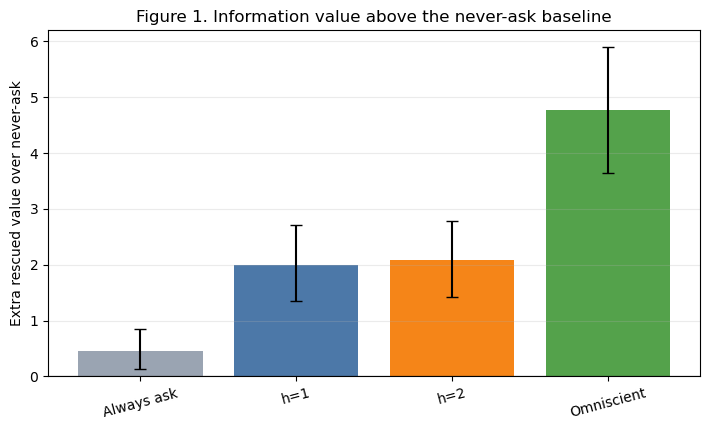

In [25]:
FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(exist_ok=True)


def bootstrap_mean(values, n_resamples=2000, seed=0):
    """Return a bootstrap 95% interval for one list of scene values."""

    values = np.asarray(values, dtype=float)
    random_state = np.random.default_rng(seed)
    sample_means = []
    for _ in range(n_resamples):
        indices = random_state.integers(0, len(values), len(values))
        sample_means.append(float(np.mean(values[indices])))
    return np.quantile(sample_means, [0.025, 0.975])


gain_over_never = {
    "Always ask": [
        row["always_ask"] - row["never"]
        for row in primary_rows
    ],
    "h=1": [
        row["h1"]["value"] - row["never"]
        for row in primary_rows
    ],
    "h=2": [
        row["h2"]["value"] - row["never"]
        for row in primary_rows
    ],
    "Omniscient": [
        row["omniscient"] - row["never"]
        for row in primary_rows
    ],
}
gain_means = np.array([
    np.mean(values) for values in gain_over_never.values()
])
gain_intervals = np.array([
    bootstrap_mean(values) for values in gain_over_never.values()
])
gain_errors = np.vstack([
    gain_means - gain_intervals[:, 0],
    gain_intervals[:, 1] - gain_means,
])


information_gap = gain_means[-1]
for name, gain in zip(gain_over_never, gain_means):
    print(
        f"{name}: +{gain:.2f} over never-ask "
        f"({gain / information_gap:.0%} of the information gap)"
    )

fig, axis = plt.subplots(figsize=(7.2, 4.4))
axis.bar(
    list(gain_over_never), gain_means,
    yerr=gain_errors, capsize=4,
    color=("#9aa4b2", "#4c78a8", "#f58518", "#54a24b"),
)
axis.axhline(0.0, color="black", linewidth=0.8)
axis.set_ylabel("Extra rescued value over never-ask")
axis.set_title("Figure 1. Information value above the never-ask baseline")
axis.tick_params(axis="x", rotation=15)
axis.grid(axis="y", alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure1_strategy_values.png", dpi=180)
plt.show()



#### Figure 2: Effect of consultation delay

The left axis shows the h=2 minus h=1 gain with paired 95% intervals; the right axis shows the share of scenes where h=2 moves first or h=1 does not ask. As delay grows, h=1 asks less often. The h=2 gain and its move-first rate peak at delay 2, then fall at delay 4 when both policies mostly stop asking.

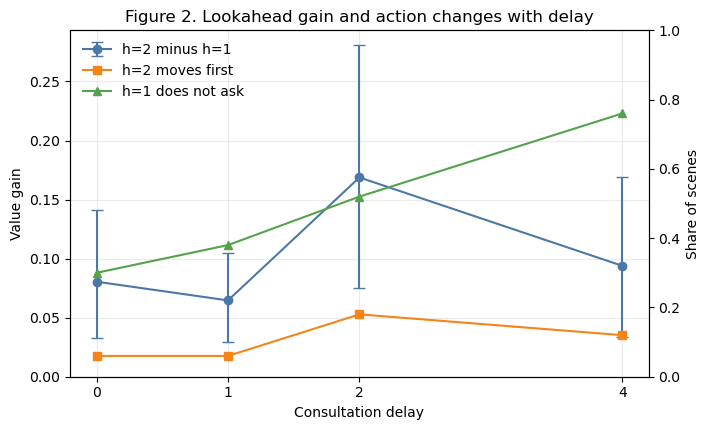

In [26]:
figure_2_rows = figure_2_data
delays = [row["delay"] for row in figure_2_rows]
gains = [row["h2_minus_h1"] for row in figure_2_rows]
gain_intervals = np.array([
    row["h2_minus_h1_interval"]
    for row in figure_2_rows
])
move_rates = [
    row["h2_moves_first_rate"]
    for row in figure_2_rows
]
no_ask_rates = [
    row["h1_does_not_ask_rate"]
    for row in figure_2_rows
]

fig, left_axis = plt.subplots(figsize=(7.2, 4.4))
left_axis.errorbar(
    delays, gains,
    yerr=np.vstack([
        np.array(gains) - gain_intervals[:, 0],
        gain_intervals[:, 1] - np.array(gains),
    ]),
    marker="o", capsize=4, color="#4c78a8",
    label="h=2 minus h=1",
)
left_axis.set_xlabel("Consultation delay")
left_axis.set_ylabel("Value gain")
left_axis.set_ylim(bottom=0)
left_axis.set_xticks(delays)
left_axis.grid(alpha=0.25)
right_axis = left_axis.twinx()
right_axis.plot(
    delays, move_rates, marker="s", color="#f58518",
    label="h=2 moves first",
)
right_axis.plot(
    delays, no_ask_rates, marker="^", color="#54a24b",
    label="h=1 does not ask",
)
right_axis.set_ylabel("Share of scenes")
right_axis.set_ylim(0, 1)
handles_left, labels_left = left_axis.get_legend_handles_labels()
handles_right, labels_right = right_axis.get_legend_handles_labels()
left_axis.legend(
    handles_left + handles_right, labels_left + labels_right,
    loc="upper left", frameon=False,
)
left_axis.set_title("Figure 2. Lookahead gain and action changes with delay")
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure2_delay_effects.png", dpi=180)
plt.show()

### Visualisation 2: Decision trace map

#### Figure 3: Seed 201 routes

The three paths are the possible outcomes when h=2 drives to pickup 1 before asking, with the probability and the next decision for each in the legend. Road 0 lies on the way, so the vehicle observes it for free. The best next question depends on what it sees: ask about road 5, ask about road 2, or not ask at all.

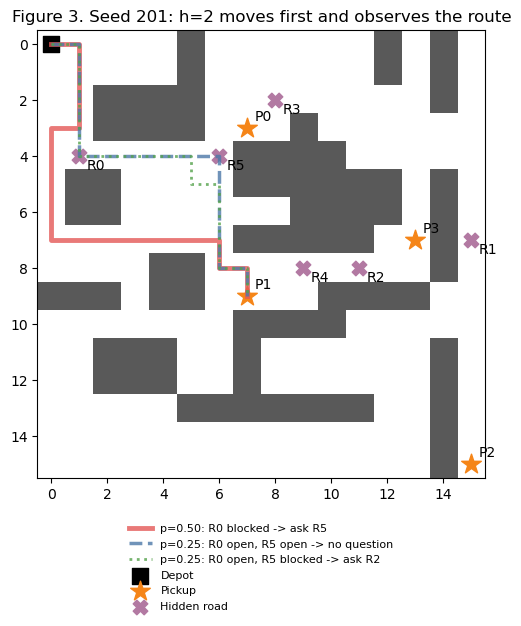

In [27]:
def drive_path(grid, scene, true_world, start, goal, evidence, settings):
    """Return the visited cells using the same movement rule as drive."""

    hidden_index = {
        cell: road
        for road, cell in enumerate(scene.hidden_roads)
    }
    current = start
    cells = [start]
    current_evidence = evidence
    maximum_steps = (
        grid.size * grid.size * 4
        + len(scene.hidden_roads) * 4
    )
    for _ in range(maximum_steps):
        if current == goal:
            return cells
        path = shortest_path(
            grid,
            cells_to_avoid(scene, current_evidence, settings),
            current,
            goal,
        )
        if path is None:
            path = shortest_path(
                grid,
                _known_blocked_cells(scene, current_evidence),
                current,
                goal,
            )
        if path is None:
            return cells
        next_cell = path[1]
        road = hidden_index.get(next_cell)
        if road is not None and road not in dict(current_evidence.seen):
            was_blocked = is_blocked(true_world, road)
            current_evidence = add_seen(
                current_evidence, road, was_blocked
            )
            if was_blocked:
                continue
        current = next_cell
        cells.append(current)
    raise RuntimeError("travel exceeded the grid-step limit")


def first_matching_world(scene, evidence):
    """Return one hidden world consistent with the observed roads."""

    seen = dict(evidence.seen)
    for world in range(1 << len(scene.hidden_roads)):
        if all(
            is_blocked(world, road) == blocked
            for road, blocked in seen.items()
        ):
            return world
    return None


trace_scene = make_scene(GRID, BOTTLENECKS, seed=201)
trace_state = initial_state(GRID, PRIMARY_SETTINGS)
first_target = 1
outcomes = _movement_outcomes(
    GRID, trace_scene, trace_state, PRIMARY_SETTINGS, first_target
)

fig, axis = plt.subplots(figsize=(7.5, 6.4))
background = np.ones((GRID.size, GRID.size))
for row, column in GRID.obstacles:
    background[row, column] = 0.35
axis.imshow(background, cmap="gray", vmin=0, vmax=1)

colours = ("#e45756", "#4c78a8", "#54a24b")
line_styles = ("-", "--", ":")
line_widths = (3.5, 2.5, 2.0)
sorted_outcomes = sorted(
    outcomes.items(), key=lambda item: item[1], reverse=True
)
for colour, line_style, line_width, (result, probability) in zip(
    colours, line_styles, line_widths, sorted_outcomes
):
    world = first_matching_world(trace_scene, result.evidence)
    cells = drive_path(
        GRID, trace_scene, world, trace_state.position,
        GRID.pickups[first_target], trace_state.evidence,
        PRIMARY_SETTINGS,
    )
    assert len(cells) - 1 == result.steps
    seen_text = ", ".join(
        f"R{road} {'blocked' if blocked else 'open'}"
        for road, blocked in result.evidence.seen
    )
    arrival_time = trace_state.time + result.steps
    child_state = State(
        position=result.end,
        time=arrival_time,
        remaining=trace_state.remaining - {first_target},
        evidence=result.evidence,
        asked=trace_state.asked,
        budget_left=trace_state.budget_left,
    )
    clear_model_caches()
    _, next_action = value_lookahead(
        GRID, trace_scene, child_state, PRIMARY_SETTINGS, horizon=1
    )
    if next_action[0] == "ask":
        decision_text = f"ask R{next_action[1]}"
    elif next_action[0] == "act":
        decision_text = "no question"
    else:
        decision_text = f"move to P{next_action[1]}"
    axis.plot(
        [cell[1] for cell in cells],
        [cell[0] for cell in cells],
        color=colour, linestyle=line_style,
        linewidth=line_width, alpha=0.8,
        label=f"p={probability:.2f}: {seen_text} -> {decision_text}",
    )

axis.scatter(
    GRID.depot[1], GRID.depot[0],
    marker="s", s=120, color="black", label="Depot"
)
for index, (row, column) in enumerate(GRID.pickups):
    axis.scatter(column, row, marker="*", s=220, color="#f58518", label="Pickup" if index == 0 else None)
    axis.annotate(
        f"P{index}", (column, row),
        xytext=(5, 5), textcoords="offset points"
    )
for road, (row, column) in enumerate(trace_scene.hidden_roads):
    axis.scatter(column, row, marker="X", s=110, color="#b279a2", label="Hidden road" if road == 0 else None)
    axis.annotate(
        f"R{road}", (column, row),
        xytext=(5, -10), textcoords="offset points"
    )

axis.set_title("Figure 3. Seed 201: h=2 moves first and observes the route")
axis.set_xlim(-0.5, GRID.size - 0.5)
axis.set_ylim(GRID.size - 0.5, -0.5)
axis.set_xticks(range(0, GRID.size, 2))
axis.set_yticks(range(0, GRID.size, 2))
axis.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=1, fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "figure3_seed201_trace.png", dpi=180, bbox_inches="tight")
plt.show()

---

## H2.2: Project Report (~1500 words)

### 1. Problem Definition and Motivation

This project studies a food-rescue coordinator operating after a disruption. One vehicle must collect food from four pickups, each with a value of 8 to 20 units and a deadline; a pickup reached after its deadline is worth nothing. Six candidate road cells may be blocked, and the vehicle only learns a road’s state when it reaches it. At the depot and at each pickup, the coordinator can act on the current route or ask a human advisor about one road. The advisor is right 80% of the time, each question uses one of two available questions, and asking can delay the vehicle. The core question is when information is worth requesting, and whether to ask immediately or keep a question for a later stop.


The stakes are uneven. A late pickup means donated food is wasted, and the people waiting for it, often in remote areas with few alternatives, receive less. A wrong road answer can send a volunteer driver towards a blockage or on an unnecessary detour.


AI is the right approach because uncertainty alone does not make a question worthwhile. If a road has a 30% chance of being blocked but both possible answers lead to the same best pickup order, asking only costs a question. A fixed shortest-path rule cannot recognise this. The decision needs an agent that keeps a belief about the roads, updates it from noisy answers and from what it sees, and plans over possible futures.


I compare five policies on the same scenes. Never-ask never consults the advisor and replans after each pickup. Always-ask asks about the first unknown road on its planned route whenever it has questions left. The myopic policy (h=1) decides whether and what to ask before leaving, but never asks again after it starts driving. The lookahead policy (h=2) can also drive to one pickup first and decide again there, so it can keep a question for later. The omniscient policy knows every road from the start and is an upper bound. The difference between omniscient and never-ask is the information gap: the most value that information could add.

The pre-registered hypothesis, fixed in H1 before any results, was that h=2 would beat h=1 by at least 10% of the information gap, with a paired 95% interval above zero. The primary setting used blockage probability 0.5, advisor accuracy 0.8, no consultation delay and a budget of two questions. This setting also tests a limit of lookahead: if keeping a question rarely changes the decision, a deeper search costs runtime without adding value.


### 2. Technical Approach

The building blocks come from the unit: A* with a Manhattan heuristic (W3) for routing, Bayes’ rule (W6) for beliefs, and expectimax, the probabilistic counterpart of minimax (W12), for decisions. What goes beyond the unit is how they are combined: the agent must decide whether information is worth gathering at all, using value of information and belief-state planning from outside the unit, and expectimax is turned from a game-playing method into a choice between asking and acting.


The agent’s belief is a probability for each of the 64 possible combinations of the six roads being open or blocked. At each decision point, expectimax compares three actions: act without asking; ask about one road; or, only for h=2, drive to a pickup first and decide again on arrival. These create two kinds of chance outcome. An advisor answer is noisy: the agent weights it by the advisor’s 80% accuracy using Bayes’ rule. A road seen while driving is certain: worlds that disagree with it are ruled out. The horizon counts movements only, because asking does not move the vehicle. So h=1 can ask both questions before leaving, while h=2 can also carry an unused question to the next stop.


Several design decisions follow. Every value is an exact expectation over all 64 worlds and both possible answers, not a random simulation, so a difference of 0.08 between h=1 and h=2 is a real difference, not sampling noise. When the agent considers driving, worlds that would show it the same thing on the way are merged into one outcome, because it can only act on what it sees; in seed 201 this turns 64 worlds into three outcomes. The vehicle reads a road’s true state only on reaching it, so the planner never sees the future. A road that has not been seen is avoided when the agent’s updated probability that it is blocked is above 0.5; this simple rule is what lets an advisor answer change the route.


I rejected two alternatives considered in H1. A full POMDP solver would need approximation choices that make it hard to tell whether a result comes from the policy or the approximation. Monte Carlo tree search would add rollout and exploration settings, and its sampling noise could hide differences as small as those measured here. Exact expectimax is slower but auditable.


The code was checked before the experiments: a reproducibility check against saved calibration results, a check that the scene generator reproduces the H1.3 preliminary scenes, six policy properties (for example, h=2 is never worse than h=1 and no policy beats the omniscient value), an A* versus BFS check on 30 small maps, a witness search and three boundary cases.


Two ideas from beyond the unit changed the design. The value of information of a question is the expected rescued value after asking, averaged over the advisor’s possible answers, minus the expected value of acting without asking; it is positive only if at least one answer would change the plan. This idea, from Howard (1966), replaced my first rule, which asked whenever a road was uncertain. Belief-state planning (Kaelbling, Littman and Cassandra, 1998) led me to keep the evidence and the remaining questions in the state, so that driving first could preserve a question for later.


H1 set a runtime trigger of 5 seconds per decision or 10 minutes overall. Evaluating one scene from the depot took 12.7 seconds for h=1 and 15.6 seconds for h=2 on average, and the full holdout took about 25 minutes, so the trigger was reached. As planned in H1, I kept the primary comparison and six hidden roads, and reduced the exploratory delay settings to 0, 1, 2 and 4. I considered upper-bound pruning but did not add it, because a new bound would need its own equivalence checks.


### 3. Results and Analysis

The primary experiment used 50 new scenes (seeds 200–249) that were not used during development. The mean rescued values were 37.61 for never-ask, 38.07 for always-ask, 39.61 for h=1, 39.69 for h=2 and 42.37 for the omniscient upper bound, so the information gap is 4.76 value units. Figure 1 shows each policy’s gain over never-ask and makes the main pattern visible: asking well is valuable, but looking further ahead adds almost nothing. h=1 recovers 2.00 of the 4.76 units, about 42% of the gap. Always-ask recovers only 0.46 and did worse than never-ask in 11 of 50 scenes, so asking without judging its value can do harm. Figure 1’s error bars are separate intervals for each policy; they overlap because scenes differ greatly in difficulty. Comparing h=1 and h=2 within each scene removes that difference: h=2 adds 0.08 value units, with a 95% bootstrap interval of [0.03, 0.14].


The hypothesis is measured by gap closure: the h=2 minus h=1 difference divided by the information gap. It was 1.7%, with a 95% interval of [0.7%, 3.0%]. The interval excludes zero, so the gain is real, but even its upper end is far below the 10% threshold. The hypothesis is therefore not supported, and the result rules out a large benefit rather than simply failing to detect one.


A small gain could also mean the h=2 code cannot find the value of waiting. The witness search rules this out. In 300 small test scenes (7×7 grid, two pickups, three unknown roads, one question), scene 122 has h=2 drive to a pickup first and score 22.450 against h=1’s 22.175. The solver therefore does recognise when keeping a question is useful.

In the primary experiment, h=2 beat h=1 in 14 of 50 scenes. In three of them, h=2’s first action was to drive to a pickup before asking; in five, both policies asked first but chose different roads; and in six, both chose exactly the same first action, so the gain must come from what h=2 does at the next stop. Figure 3 shows seed 201, the move-first case with the second-largest gain (+0.94).


In seed 201, h=1 asks about road 5 at the depot. h=2 instead drives to pickup 1 without asking, because road 0 lies on the way and the vehicle can see it for free. The trip has three possible outcomes. Each one reaches pickup 1 on time and collects its value of 20; what differs is what the vehicle has seen and therefore what it does next:

| Seen on the way | Probability | Next decision at pickup 1 | Expected value of the rest of the route |
| --- | --- | --- | --- |
| road 0 blocked | 0.50 | ask about road 5 | 30.375 |
| roads 0 and 5 open | 0.25 | do not ask | 41.500 |
| road 0 open, road 5 blocked | 0.25 | ask about road 2 | 27.265 |


Weighting each outcome by its probability gives h=2’s expected value:
0.50 × (20 + 30.375) + 0.25 × (20 + 41.500) + 0.25 × (20 + 27.265) = 52.379,
which matches the solver’s value for h=2 exactly and is 0.94 higher than h=1’s 51.444. The best question depends on what the vehicle sees on the way, and h=1 cannot plan for that because it never asks after it starts driving.


To find out why h=2 helped in its best cases, I reran the four scenes with the largest gains (218, 201, 212 and 248), each time changing one setting: a perfect advisor, or no questions at all. With no questions, h=1 and h=2 were equal in all four, as expected. With a perfect advisor, the gain disappeared in seeds 201 and 248; in seed 201 both policies reached 55.0, the omniscient value. When answers are certain, asking at the depot already gives complete information, so there is no reason to wait and look first. This suggests that in these scenes h=2 was using a free, certain observation in place of a noisy answer. In seeds 212 and 218 the gain remained (0.31 and 1.31), so it does not depend on advisor noise; it comes from choosing better which road to ask about at which stop. These four cases are illustrative, not statistical evidence.


The primary test assumes that asking costs no time, which may be exactly why keeping a question rarely helps. Figure 2 shows the exploratory delay experiment, where each question adds a fixed number of steps to the clock. As delay grew, h=1 chose not to ask in more scenes: 30% at delay 0, 38% at 1, 52% at 2 and 76% at 4. The h=2 gain was largest at delay 2, at 0.17, which is also where h=2 drove first most often (18% of scenes). A plausible reason is that a delay at the depot pushes back all four pickups, while a delay after the first pickup affects only the remaining three, so asking later is cheaper. At delay 4 both policies mostly stopped asking, which left little room for lookahead to help. Gap closure was 1.7%, 1.4%, 3.5% and 2.0% at delays 0, 1, 2 and 4, so no setting reached the 10% threshold. The accuracy-mismatch and fairness results are discussed in Sections 4 and 5.


The most surprising finding is that the deeper search rarely changed the first decision: h=1 and h=2 chose the same first action in 42 of 50 scenes. Choosing whether to ask worked; planning when to ask added little. The evidence above explains why. With no delay, a question asked at the depot gives exactly the same information as the same question asked later, so keeping a question only pays when something seen on the way changes which question is best. That needs an unknown road on the route to the next pickup whose state changes the value of the remaining questions. This happened rarely: h=2 drove first in only three of 50 scenes and beat h=1 in only two of 300 small scenes. 


### 4. Limitations and Future Work

Independent roads. Each hidden road is blocked independently. Real damage is often clustered: if one road floods, its neighbours probably have too. In that case, seeing one road would also be evidence about nearby roads, so driving first and looking would be worth more than in this model. The small lookahead gain found here may not hold under clustered damage.


A fixed route threshold. An unseen road is avoided whenever its probability of being blocked is above 0.5, regardless of the cost of avoiding it. The same 60% probability can justify a two-step detour but not a twenty-step one, so the rule can choose a poor route when detour costs vary widely. H1 planned to compare thresholds of 0.3, 0.5 and 0.7, but this was dropped when the runtime trigger was reached.

Wrong advisor accuracy. The agent assumes it knows how reliable the advisor is. In a 10-scene test with h=1, an agent that assumed 80% accuracy when the true accuracy was 60% scored 34.15, against 34.53 for an agent that knew the true accuracy and 34.10 for never-ask. The mismatch cost of 0.38 is 1.1% of the calibrated value, below the 5% limit set in H1, but it removed almost all of the value of asking: the gain over never-ask fell from 0.43 to 0.05. The mechanism is over-trust. The agent chooses pickup orders and questions as if each answer is right 80% of the time, so it commits to plans that depend on answers that are wrong 40% of the time. In three of the ten scenes it did worse than never asking.


A two-step horizon. h=2 can keep a question for one later stop only. With a larger budget or more pickups, a question might be worth keeping for two or more stops, which this search cannot represent.


Synthetic deadlines. Every pickup’s deadline is its arrival time on a reference tour plus 0–20 steps of slack. The same slack range is a much smaller share of a 34-step trip than of a 12-step trip, so the farthest pickup has the tightest deadline relative to its distance. This may exaggerate the remote lateness reported in Section 5.


With more time, I would first add upper-bound pruning, verified to give the same results, to make the search fast enough for h=3 and the planned threshold comparison. I would then replace the 0.5 threshold with a rule based on each detour’s expected cost, test correlated road damage, compute the query-synergy metric planned in H1, and treat the advisor’s accuracy as uncertain rather than known.


### 5. Ethical Reflection


If deployed, the system would affect four groups: the communities waiting for food, the donors whose food is wasted if a pickup is late, the volunteer drivers sent towards blocked roads by wrong answers, and the advisor whose time each question uses. The failure that matters most is systematic: one community repeatedly being served late, because that harm accumulates and is hidden inside a good total. C2 asked of a classifier, “accurate for whom?”; here the question is “rescued for whom?”


The timeliness analysis shows this happening. Under never-ask, the two central pickups were late 13% of the time and the two remote pickups 53%, a 40-point gap that exceeds the 20-point flag set in H1. The gap comes mainly from one site. Pickup 2 at (15,15), 34 steps from the depot, was on time in only 15.8% of cases. Even the omniscient planner served it on time in only 39.3%, so most of the disadvantage is structural: its distance, its deadline and an objective that may sacrifice it to save more value elsewhere. Uncertainty then costs it a further 23.4 points, while each of the other three pickups loses at most 3.7.


In C2’s terms, this violates demographic parity: the rate of on-time service differs sharply between groups defined by location, which the communities cannot change. Equalised odds does not apply, because there is no ground-truth label to condition on. This creates a direct tension. Maximising total rescued value is the stated objective, but it places the largest cost on the most remote community, and even the choice of which road to ask about decides which pickup is protected from uncertainty. A minimum-service constraint or a higher priority weight for remote sites, as planned in the H1 risk register, would narrow the gap but reduce total rescued value. As C2 concluded, choosing between these is a value judgement, not a technical one: the coordinator and the affected communities should decide it, not the optimiser.


C4’s deployment framework sets the conditions for any use. Performance should be reported per site, not only as a total. The advisor-accuracy test in Section 4 is a form of distribution shift: if real advisors are less reliable than assumed, the value of asking quietly disappears, so answer accuracy must be monitored. And for the Petrov question, if the system is confidently wrong, the coordinator must be informed and authorised to override it. The evidence is limited to four pickups and the never-ask policy, so it is a warning signal rather than a general claim.


### 6. AI Use Statement

I used Claude as a discussion and review tool during October 2026. It helped me understand the rubric, compare design options, suggest validation checks, and identify parts of the reasoning that needed testing. I wrote and edited the final implementation and made the final scope and design decisions.  

During these discussions, Claude suggested several intermediate implementation ideas and recurrences. I tested them instead of accepting them automatically, and this process exposed four problems: an action recurrence that lost the remaining question budget, a route that used the true shortest path and leaked information, a planner that ignored belief so the value of information was zero, and duplicated caching that made timing unfair. I also rejected the suggestion to ask whenever a road was uncertain, because uncertainty alone does not mean an answer will change the plan.

---

## Submission Checklist

- [ ] Recap of H1 scope (and any pivot) at the top
- [ ] Working notebook with data, implementation, 2+ experiments, 2+ visualisations
- [ ] Project report (~1500 words) covering all 6 sections
- [ ] Implementation demonstrates HD-level depth beyond earlier task work
- [ ] Ethical reflection connects to C2 or C4
- [ ] AI use statement shows critical evaluation
- [ ] Code is readable, reproducible, documented
- [ ] Uploaded to OnTrack and marked **Ready for Feedback**
- [ ] H3 interview booking confirmed for W14

---

*FIT1061 HD Task H2: Comprehensive Project: Implementation & Review*